# SELEX Data Preprocessing and Exploratory Data Analysis

## 1. Introduction

The objective of this notebook is to preprocess and explore the data used in the DNAffinity project, focusing on the relationship between DNA sequence features and protein-DNA binding affinity.

The analysis focuses on three main data sources:

- **DNA structural features:** Average helical parameters and stiffness matrices obtained from molecular dynamics simulations for tetramers and hexamers.
- **Electrostatic features:** Electrostatic potential and ion-related descriptors.
- **HT-SELEX data:** Experimental sequencing counts and estimated binding affinities for 10-mer DNA sequences.

The tetramer and hexamer datasets will be analysed independently. Each row will represent a unique DNA sequence, while the columns will contain its corresponding numerical features.

The notebook will first examine the structure and quality of the available data, followed by exploratory analyses to investigate feature distributions, variability, correlations and dimensionality. Finally, the SELEX data will be explored to investigate potential relationships between DNA structural properties and binding affinity.

The purpose of this notebook is to understand the available data and identify relevant patterns before proceeding to model development.

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Repository root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

print("Repository:", ROOT)

Repository: /home/oscar/DNAffinity


## 2. Setup and imports

In this section, we import the Python libraries required for data manipulation, numerical analysis and visualisation.

We also define the root directory of the DNAffinity repository, which will be used to access the different datasets throughout the notebook.

In [9]:
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Repository root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

print("Repository:", ROOT)

Repository: /home/oscar/DNAffinity


## 3. Data loading

In this section, we identify and load the HT-SELEX datasets required for the analysis.

The datasets contain information about DNA 10-mer sequences, including their estimated binding affinity, observed sequencing counts, expected counts and associated standard errors.

We will focus exclusively on the SELEX data available for the selected transcription factors. First, we inspect the directory structure to identify the available proteins and their corresponding SELEX cycles. Then, we select the appropriate datasets for further analysis.

In [11]:
# Define the SELEX data directory
SELEX_DIR = ROOT / "data" / "selex"

# List available files
for path in sorted(SELEX_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(ROOT))

data/selex/hexamer/avg_hexamer.dat
data/selex/hexamer/electrostatic_hexamer.dat
data/selex/hexamer/fce_hexamer.dat
data/selex/hexamer/input_hexamer.dat
data/selex/hexamer/ion_vec_hexamer.dat
data/selex/tetramer/avg_tetramer.dat
data/selex/tetramer/electrostatic_tetramer.dat
data/selex/tetramer/fce_tetramer.dat
data/selex/tetramer/input_tetramer.dat
data/selex/tetramer/ion_vec_tetramer.dat
data/selex/transcription_factors/Gata4/4.txt
data/selex/transcription_factors/Zfp24/5.txt
data/selex/transcription_factors/arid3/6.txt
data/selex/transcription_factors/hoxd1/3.txt
data/selex/transcription_factors/nkx3/6.txt
data/selex/transcription_factors/pax3-like/5.txt
data/selex/transcription_factors/six1/5.txt
data/selex/transcription_factors/tbx15/5.txt
data/selex/transcription_factors/telf/5.txt
data/selex/transcription_factors/uncxb/5.txt
data/selex/transcription_factors/xbpc/5.txt


## 3. Data loading

In this section, we load the datasets required for the exploratory data analysis.

The data consist of two main groups:

- **DNA sequence features:** Structural and physicochemical descriptors for all possible tetramers and hexamers, including average helical parameters, stiffness matrices, electrostatic properties and ion-related descriptors.
- **HT-SELEX data:** Experimental sequencing results for different transcription factors. Each dataset corresponds to a selected SELEX cycle, generally the penultimate cycle, as previously determined.

The datasets will initially be loaded separately. In subsequent sections, the structural and physicochemical descriptors will be integrated into two independent feature tables: one for tetramers and another for hexamers.

In [12]:
# Define directories
TETRAMER_DIR = SELEX_DIR / "tetramer"
HEXAMER_DIR = SELEX_DIR / "hexamer"

# Load tetramer datasets
avg_tetramer = pd.read_csv(TETRAMER_DIR / "avg_tetramer.dat", sep=r"\s+")
fce_tetramer = pd.read_csv(TETRAMER_DIR / "fce_tetramer.dat", sep=r"\s+")
electrostatic_tetramer = pd.read_csv(TETRAMER_DIR / "electrostatic_tetramer.dat", sep=r"\s+")
ion_vec_tetramer = pd.read_csv(TETRAMER_DIR / "ion_vec_tetramer.dat", sep=r"\s+")

# Load hexamer datasets
avg_hexamer = pd.read_csv(HEXAMER_DIR / "avg_hexamer.dat", sep=r"\s+")
fce_hexamer = pd.read_csv(HEXAMER_DIR / "fce_hexamer.dat", sep=r"\s+")
electrostatic_hexamer = pd.read_csv(HEXAMER_DIR / "electrostatic_hexamer.dat", sep=r"\s+")
ion_vec_hexamer = pd.read_csv(HEXAMER_DIR / "ion_vec_hexamer.dat", sep=r"\s+")

In [13]:
# Selected SELEX cycle for each transcription factor
selex_cycles = {
    "Gata4": 4,
    "Zfp24": 5,
    "arid3": 6,
    "hoxd1": 3,
    "nkx3": 6,
    "pax3-like": 5,
    "six1": 5,
    "tbx15": 5,
    "telf": 5,
    "uncxb": 5,
    "xbpc": 5
}

# Load SELEX datasets
selex_data = {}

for protein, cycle in selex_cycles.items():
    path = SELEX_DIR / "transcription_factors" / protein / f"{cycle}.txt"
    selex_data[protein] = pd.read_csv(path, sep="\t")

print(f"Loaded {len(selex_data)} transcription factor datasets.")

Loaded 11 transcription factor datasets.


In [14]:
print("Tetramer datasets:")
for name, df in {
    "Average": avg_tetramer,
    "Stiffness": fce_tetramer,
    "Electrostatic": electrostatic_tetramer,
    "Ion vector": ion_vec_tetramer
}.items():
    print(f"{name}: {df.shape}")

print("\nHexamer datasets:")
for name, df in {
    "Average": avg_hexamer,
    "Stiffness": fce_hexamer,
    "Electrostatic": electrostatic_hexamer,
    "Ion vector": ion_vec_hexamer
}.items():
    print(f"{name}: {df.shape}")

print("\nSELEX datasets:")
for protein, df in selex_data.items():
    print(f"{protein}: {df.shape}")

Tetramer datasets:
Average: (256, 7)
Stiffness: (256, 36)
Electrostatic: (255, 6)
Ion vector: (256, 7)

Hexamer datasets:
Average: (4096, 7)
Stiffness: (4096, 36)
Electrostatic: (4096, 6)
Ion vector: (4096, 11)

SELEX datasets:
Gata4: (126624, 6)
Zfp24: (406165, 6)
arid3: (273249, 6)
hoxd1: (887634, 7)
nkx3: (963575, 6)
pax3-like: (427916, 6)
six1: (944350, 6)
tbx15: (25991, 6)
telf: (691492, 6)
uncxb: (234129, 6)
xbpc: (463571, 6)


### 3.4. Combined DNA feature datasets

The `input_tetramer.dat` and `input_hexamer.dat` files contain integrated structural and physicochemical descriptors for all possible tetramer and hexamer sequences, respectively.

Each row represents a unique DNA sequence, while the remaining columns describe its structural and physicochemical properties. The datasets contain four main groups of features:

#### 1. Average helical parameters (AVG)

These six parameters describe the average structural configuration of DNA at each base-pair step. They are obtained from molecular dynamics simulations and represent the equilibrium values of the six degrees of freedom used to describe DNA geometry.

The parameters are divided into two categories:

- **Translational parameters:**
  - **Shift:** Displacement along the x-axis.
  - **Slide:** Displacement along the y-axis.
  - **Rise:** Displacement along the z-axis.

- **Rotational parameters:**
  - **Tilt:** Rotation around the x-axis.
  - **Roll:** Rotation around the y-axis.
  - **Twist:** Rotation around the z-axis.

These parameters describe how the relative position and orientation of neighbouring base pairs vary depending on the DNA sequence.

#### 2. Stiffness matrix (FCE)

The stiffness matrix describes the mechanical properties of DNA, specifically how resistant it is to structural deformation.

It is represented by a 6 × 6 matrix containing 36 elements, corresponding to the six translational and rotational degrees of freedom.

- **Diagonal elements:** Describe the stiffness associated with individual movements, such as shift, slide or twist.
- **Off-diagonal elements:** Describe the coupling between different movements, indicating how deformation in one direction can be associated with deformation in another.

Together, these values provide information about the mechanical flexibility and deformation behaviour of DNA.

#### 3. Electrostatic descriptors

These five descriptors represent the electrostatic patterns associated with the chemical properties of DNA bases.

The method assigns numerical values to different chemical features:

- Hydrogen-bond acceptors: −1
- Hydrophobic sites: 0
- Hydrogen-bond donors: +1

For each tetramer, the contributions of overlapping DNA base patterns are summed along five columns, resulting in five electrostatic descriptors (`e1`–`e5`).

These descriptors capture differences in the chemical patterns presented by DNA, which can contribute to protein–DNA recognition through direct interactions.

#### 4. Ion-related descriptors

The datasets also include six additional descriptors derived from the ion vector data (`m1`–`m3` and `j1`–`j3`).

These features provide additional information related to ions associated with the DNA structural environment. However, their precise physical interpretation has not yet been established and will require further investigation.

Overall, the combined datasets provide complementary information about DNA geometry, mechanical properties and chemical characteristics, which may contribute to protein–DNA recognition.

#### Comparison between tetramer and hexamer features

Both datasets share the same 53 features, covering average helical parameters, stiffness, electrostatic descriptors and ion-related properties.

However, the hexamer dataset contains four additional features: `m0`, `m4`, `j0` and `j4`.

These additional descriptors are associated with the ion vector data and may reflect the additional positions available for ion-related information in longer DNA sequences.

Consequently, the tetramer and hexamer datasets contain 53 and 57 numerical features, respectively.

In [22]:
# Load combined tetramer and hexamer feature tables

input_tetramer = pd.read_csv(
    TETRAMER_DIR / "input_tetramer.dat",
    sep=r"\s+"
)

input_hexamer = pd.read_csv(
    HEXAMER_DIR / "input_hexamer.dat",
    sep=r"\s+"
)

# Load combined tetramer and hexamer feature tables

input_tetramer = pd.read_csv(
    TETRAMER_DIR / "input_tetramer.dat",
    sep=r"\s+"
)

input_hexamer = pd.read_csv(
    HEXAMER_DIR / "input_hexamer.dat",
    sep=r"\s+"
)

In [23]:
print("Tetramer dataset:")
print("Dimensions:", input_tetramer.shape)
print("Number of unique sequences:", input_tetramer["SEQUENCE"].nunique())
print("Number of features:", input_tetramer.shape[1] - 1)

print("\nHexamer dataset:")
print("Dimensions:", input_hexamer.shape)
print("Number of unique sequences:", input_hexamer["SEQUENCE"].nunique())
print("Number of features:", input_hexamer.shape[1] - 1)

Tetramer dataset:
Dimensions: (256, 54)
Number of unique sequences: 256
Number of features: 53

Hexamer dataset:
Dimensions: (4096, 58)
Number of unique sequences: 4096
Number of features: 57


In [24]:
tetramer_features = set(input_tetramer.columns) - {"SEQUENCE"}
hexamer_features = set(input_hexamer.columns) - {"SEQUENCE"}

print("Features only in tetramers:")
print(sorted(tetramer_features - hexamer_features))

print("\nFeatures only in hexamers:")
print(sorted(hexamer_features - tetramer_features))

Features only in tetramers:
[]

Features only in hexamers:
['j0', 'j4', 'm0', 'm4']


In [27]:
for i, column in enumerate(input_hexamer.columns):
    print(f"{i}: {column}")

0: SEQUENCE
1: SHIFT
2: SLIDE
3: RISE
4: TILT
5: ROLL
6: TWIST
7: SHIFT.SHIFT
8: SHIFT.SLIDE
9: SHIFT.RISE
10: SHIFT.TILT
11: SHIFT.ROLL
12: SHIFT.TWIST
13: SLIDE.SHIFT
14: SLIDE.SLIDE
15: SLIDE.RISE
16: SLIDE.TILT
17: SLIDE.ROLL
18: SLIDE.TWIST
19: RISE.SHIFT
20: RISE.SLIDE
21: RISE.RISE
22: RISE.TILT
23: RISE.ROLL
24: RISE.TWIST
25: TILT.SHIFT
26: TILT.SLIDE
27: TILT.RISE
28: TILT.TILT
29: TILT.ROLL
30: TILT.TWIST
31: ROLL.SHIFT
32: ROLL.SLIDE
33: ROLL.RISE
34: ROLL.TILT
35: ROLL.ROLL
36: ROLL.TWIST
37: TWIST.SHIFT
38: TWIST.SLIDE
39: TWIST.RISE
40: TWIST.TILT
41: TWIST.ROLL
42: TWIST.TWIST
43: e1
44: e2
45: e3
46: e4
47: e5
48: m0
49: m1
50: m2
51: m3
52: m4
53: j0
54: j1
55: j2
56: j3
57: j4


## 4. Initial Data Inspection

Before performing exploratory data analysis, it is important to assess the quality and structure of the datasets.

In this section, we examine the tetramer and hexamer feature tables to identify potential data quality issues, including missing values, duplicated sequences and unexpected data types.

We also calculate descriptive statistics to obtain an initial overview of the numerical features and their variability.

The data type inspection shows that both datasets have the expected structure.

The `SEQUENCE` column is stored as an object (string), while all numerical descriptors are represented as either integers (`int64`) or floating-point numbers (`float64`).

The tetramer dataset contains 48 floating-point and 5 integer features, whereas the hexamer dataset contains 52 floating-point and 5 integer features.

No unexpected data types were identified.

Both datasets were checked for missing values, and no missing observations were found.

Therefore, all 256 tetramer sequences and 4,096 hexamer sequences have complete feature information. No missing-value imputation or removal is required.

### 4.4. Descriptive statistics

In this section, we examine the descriptive statistics of the numerical features in both datasets.

We calculate the mean, standard deviation, minimum, maximum and quartiles for each feature.

These statistics provide an initial understanding of the distribution and variability of the structural and physicochemical descriptors. They can also help identify features with very different numerical scales or potentially unusual values.

In [33]:
# Descriptive statistics for tetramers
tetramer_stats = input_tetramer.drop(columns="SEQUENCE").describe().T

# Descriptive statistics for hexamers
hexamer_stats = input_hexamer.drop(columns="SEQUENCE").describe().T

#display(tetramer_stats)
#display(hexamer_stats)

#### Initial observations

The descriptive statistics reveal several interesting characteristics of the structural and physicochemical features.

**Average helical parameters (AVG)** show similar distributions between tetramers and hexamers. SHIFT and TILT have means close to zero, whereas SLIDE has a negative mean. RISE presents relatively low variability, while ROLL shows a considerably wider range of values. TWIST has a mean of approximately 34° in both datasets.

**Stiffness parameters (FCE)** present different numerical scales depending on the type of deformation and coupling represented. The diagonal elements, such as RISE.RISE, generally have larger values than some rotational components. The descriptive statistics also show identical distributions for symmetric pairs of matrix elements, such as SHIFT.SLIDE and SLIDE.SHIFT.

**Electrostatic descriptors** contain integer values, reflecting their construction from the contributions of hydrogen-bond acceptors, donors and hydrophobic sites. Their ranges are wider in hexamers (−6 to +6) than in tetramers (−4 to +4), consistent with the longer sequence length.

**Ion-related descriptors** consist of six positive real-valued features for tetramers (`m1`–`m3` and `j1`–`j3`) and ten for hexamers (`m0`–`m4` and `j0`–`j4`). Their values range from 1.7 to 19.9 in tetramers and from 1.2 to 27.5 in hexamers. Since the repository does not document their precise physical meaning, no specific interpretation is assigned to individual columns.

Overall, the results show that the datasets contain features with different numerical scales and variability. These differences will be important to consider in subsequent analyses, particularly correlation analysis and dimensionality reduction.

## 5. Exploratory Data Analysis

In this section, we explore the distributions of the structural and physicochemical features in the tetramer and hexamer datasets.

We examine the different feature groups separately to better understand their variability, distribution patterns and potential differences between tetramers and hexamers.

### 5.1. Average helical parameters (AVG)

We first examine the distributions of the six average helical parameters: SHIFT, SLIDE, RISE, TILT, ROLL and TWIST.

These parameters describe the relative position and orientation of neighbouring DNA base pairs. Visualising their distributions allows us to assess their variability, identify potential outliers and compare the structural properties of tetramers and hexamers.

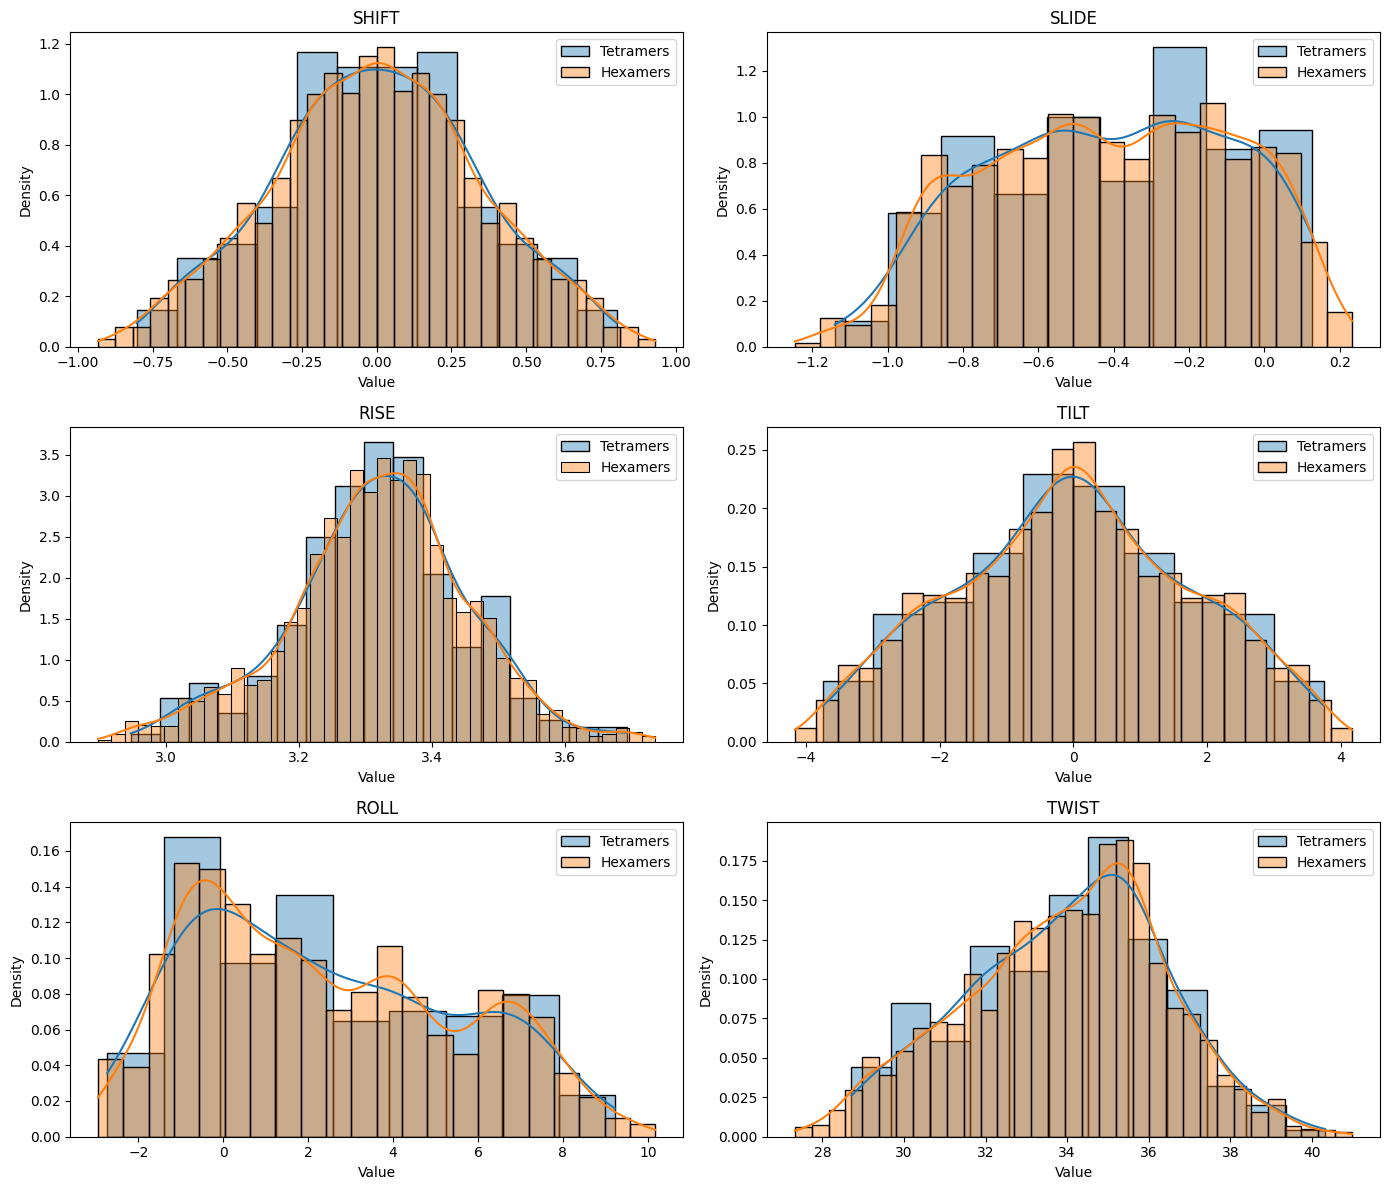

In [36]:
avg_features = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, feature in zip(axes.flat, avg_features):
    sns.histplot(input_tetramer[feature], kde=True, stat="density",
                 label="Tetramers", ax=ax, alpha=0.4)
    
    sns.histplot(input_hexamer[feature], kde=True, stat="density",
                 label="Hexamers", ax=ax, alpha=0.4)
    
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()
fig.savefig("avg_distributions.png", dpi=300, bbox_inches="tight")

#### Observations

The distributions of the average helical parameters show some differences in their shape and variability.

SHIFT and TILT display approximately symmetric, bell-shaped distributions centred around zero. RISE and TWIST also show relatively bell-shaped distributions, with values concentrated around 3.32 Å and 34°, respectively.

SLIDE presents a slightly irregular distribution, with a negative mean and a tail towards lower values. ROLL shows a more asymmetric distribution, with a broader spread and a tail towards higher positive values.

The tetramer and hexamer distributions overlap considerably, indicating that their average helical parameters have similar overall distributions.

Overall, RISE shows relatively low variability, whereas ROLL presents a broader distribution. This suggests that different aspects of DNA geometry exhibit different degrees of sequence-dependent variability.

#### 5.2.1. Diagonal elements

The diagonal elements of the stiffness matrix describe the resistance of DNA to deformation along each of the six degrees of freedom: SHIFT, SLIDE, RISE, TILT, ROLL and TWIST.

We examine their distributions to compare the mechanical properties of tetramers and hexamers and assess the variability associated with each type of deformation.

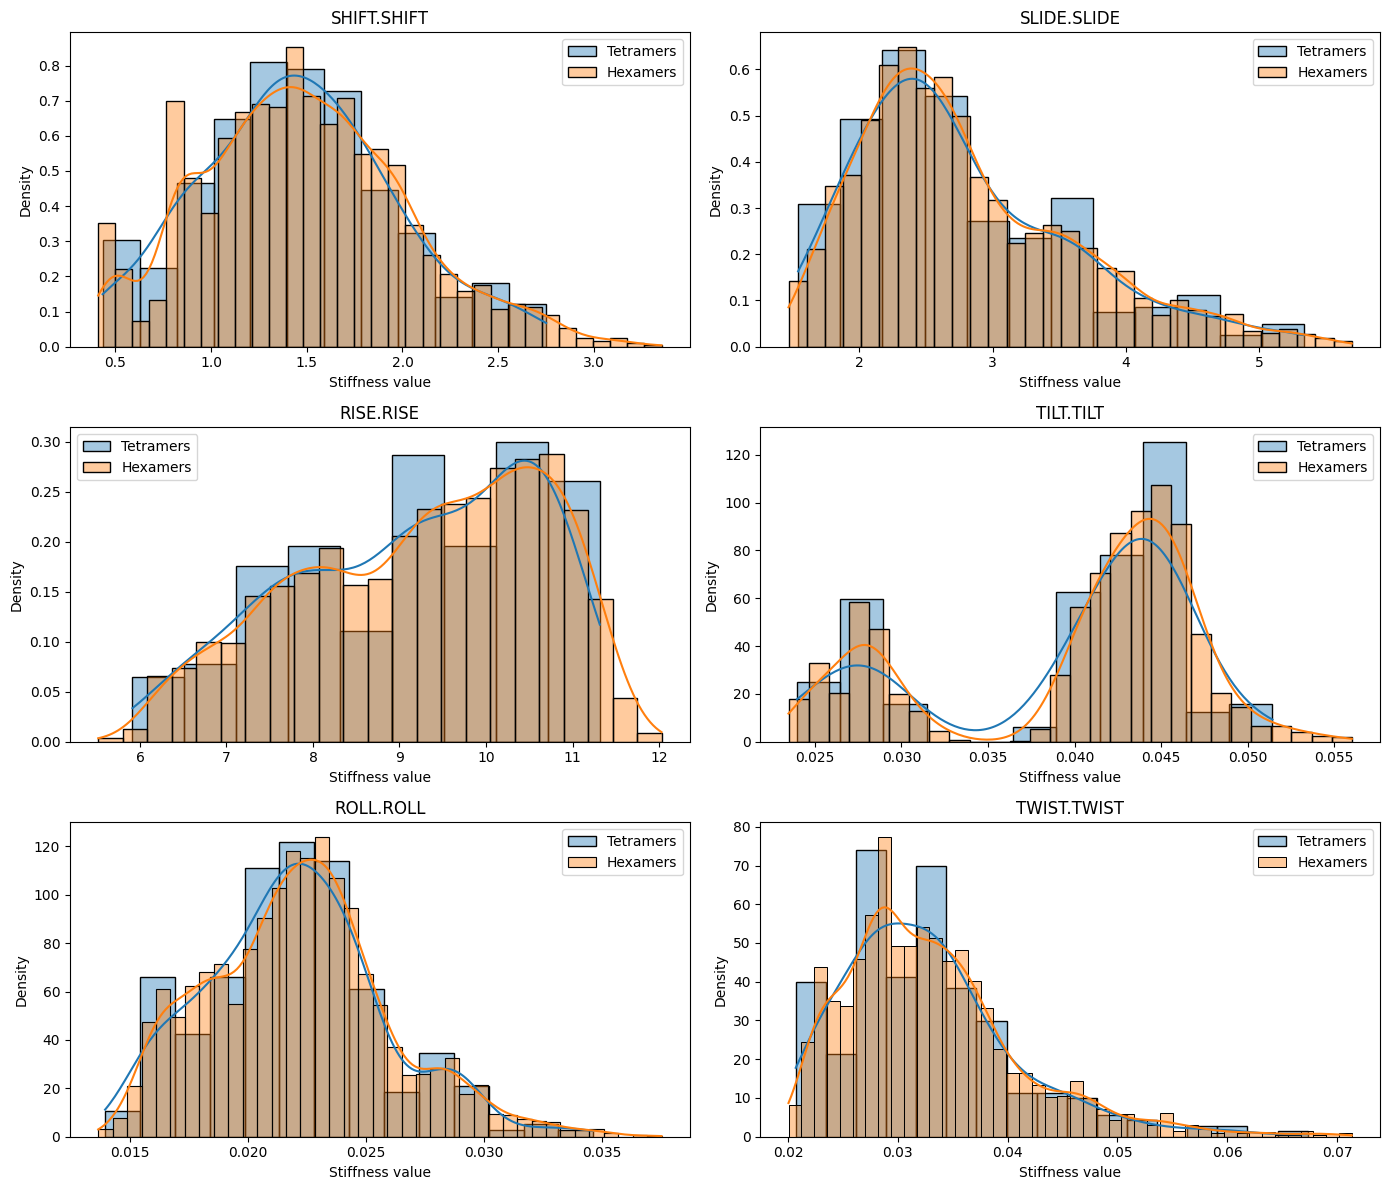

In [37]:
diagonal_features = [
    "SHIFT.SHIFT",
    "SLIDE.SLIDE",
    "RISE.RISE",
    "TILT.TILT",
    "ROLL.ROLL",
    "TWIST.TWIST"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, feature in zip(axes.flat, diagonal_features):
    sns.histplot(input_tetramer[feature], kde=True, stat="density",
                 label="Tetramers", ax=ax, alpha=0.4)

    sns.histplot(input_hexamer[feature], kde=True, stat="density",
                 label="Hexamers", ax=ax, alpha=0.4)

    ax.set_title(feature)
    ax.set_xlabel("Stiffness value")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
fig.savefig("fce_diagonal_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The diagonal stiffness elements show different distribution patterns depending on the type of DNA deformation.

SHIFT.SHIFT presents a relatively concentrated, unimodal distribution, with a slight right tail. SLIDE.SLIDE and TWIST.TWIST show more noticeable right-skewed distributions, indicating the presence of sequences with higher stiffness values.

RISE.RISE exhibits a broader distribution, with values concentrated mainly between 9 and 11. TILT.TILT is particularly interesting, as it shows a bimodal distribution with two distinct peaks. Finally, ROLL.ROLL presents a relatively concentrated distribution around 0.022–0.024.

The tetramer and hexamer distributions overlap considerably across all six parameters, indicating similar overall distributions between the two datasets.

Overall, the diagonal stiffness elements show different degrees of variability and distribution patterns, suggesting that the mechanical properties associated with different DNA movements are not uniform across sequences.

#### 5.2.2. Off-diagonal elements

The off-diagonal elements of the stiffness matrix describe the coupling between different translational and rotational movements of DNA.

Unlike the diagonal elements, which describe individual deformation modes, these values provide information about how different movements are mechanically related.

Since the stiffness matrix is symmetric, only the 15 unique off-diagonal elements are considered to avoid analysing duplicated information.

We examine their distributions to investigate the variability and patterns of coupling between different DNA movements.

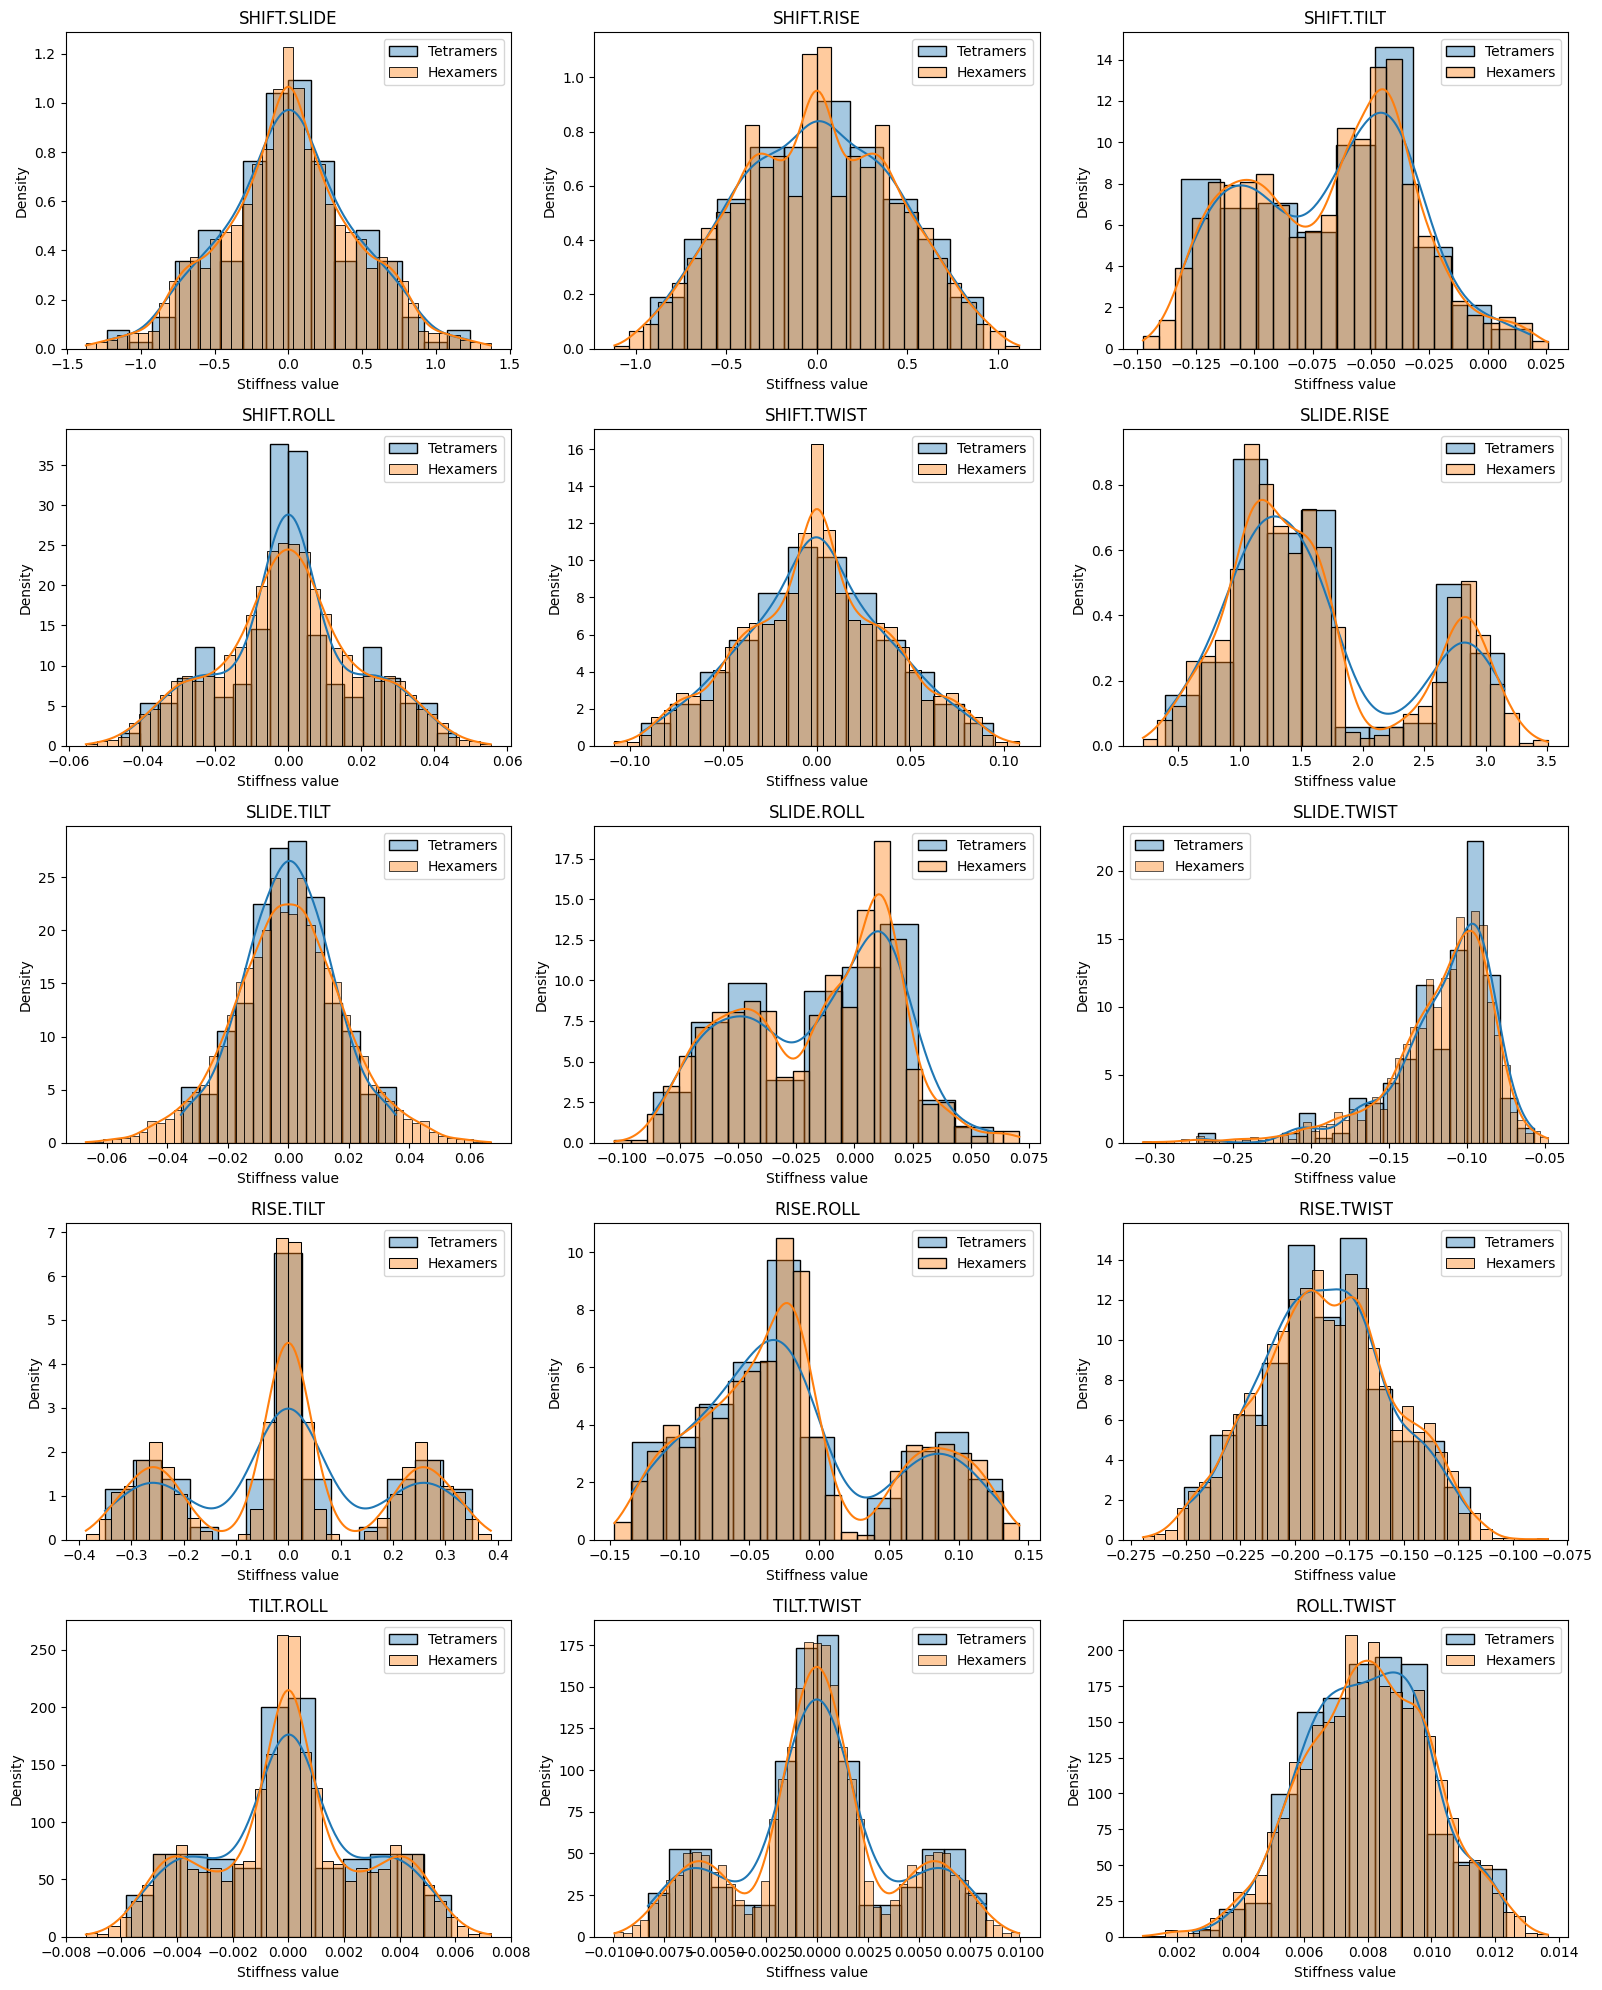

In [38]:
import itertools

degrees = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]

off_diagonal_features = [
    f"{a}.{b}"
    for a, b in itertools.combinations(degrees, 2)
]

fig, axes = plt.subplots(5, 3, figsize=(16, 20))

for ax, feature in zip(axes.flat, off_diagonal_features):
    sns.histplot(input_tetramer[feature], kde=True, stat="density",
                 label="Tetramers", ax=ax, alpha=0.4)

    sns.histplot(input_hexamer[feature], kde=True, stat="density",
                 label="Hexamers", ax=ax, alpha=0.4)

    ax.set_title(feature)
    ax.set_xlabel("Stiffness value")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
fig.savefig("fce_off_diagonal_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The off-diagonal stiffness elements show a variety of distribution patterns, reflecting differences in the coupling between DNA deformation modes.

Several features, such as SHIFT.SLIDE, SHIFT.RISE and SHIFT.TWIST, show approximately symmetric distributions centred around zero. Other features, including SLIDE.TWIST, RISE.TWIST and ROLL.TWIST, are predominantly negative or positive.

Several coupling terms also exhibit multimodal distributions, with two or more distinct concentration regions. This is particularly noticeable for SHIFT.TILT, SLIDE.RISE, SLIDE.ROLL and RISE.ROLL, suggesting that their values vary across different sequence environments.

The tetramer and hexamer distributions overlap considerably for most features, indicating similar overall patterns of mechanical coupling.

Overall, the off-diagonal elements show substantial differences in distribution shape and variability. These results highlight the complexity of the mechanical interactions between different DNA deformation modes.

### 5.3. Electrostatic descriptors

In this section, we examine the distributions of the five electrostatic descriptors (`e1`–`e5`).

These features represent chemical patterns associated with DNA bases, which may contribute to direct protein–DNA recognition through interactions such as hydrogen bonding.

Unlike the previous structural parameters, these descriptors contain discrete integer values resulting from the combination of contributions assigned to different chemical groups.

We compare their distributions between tetramers and hexamers to investigate differences in their range and variability.

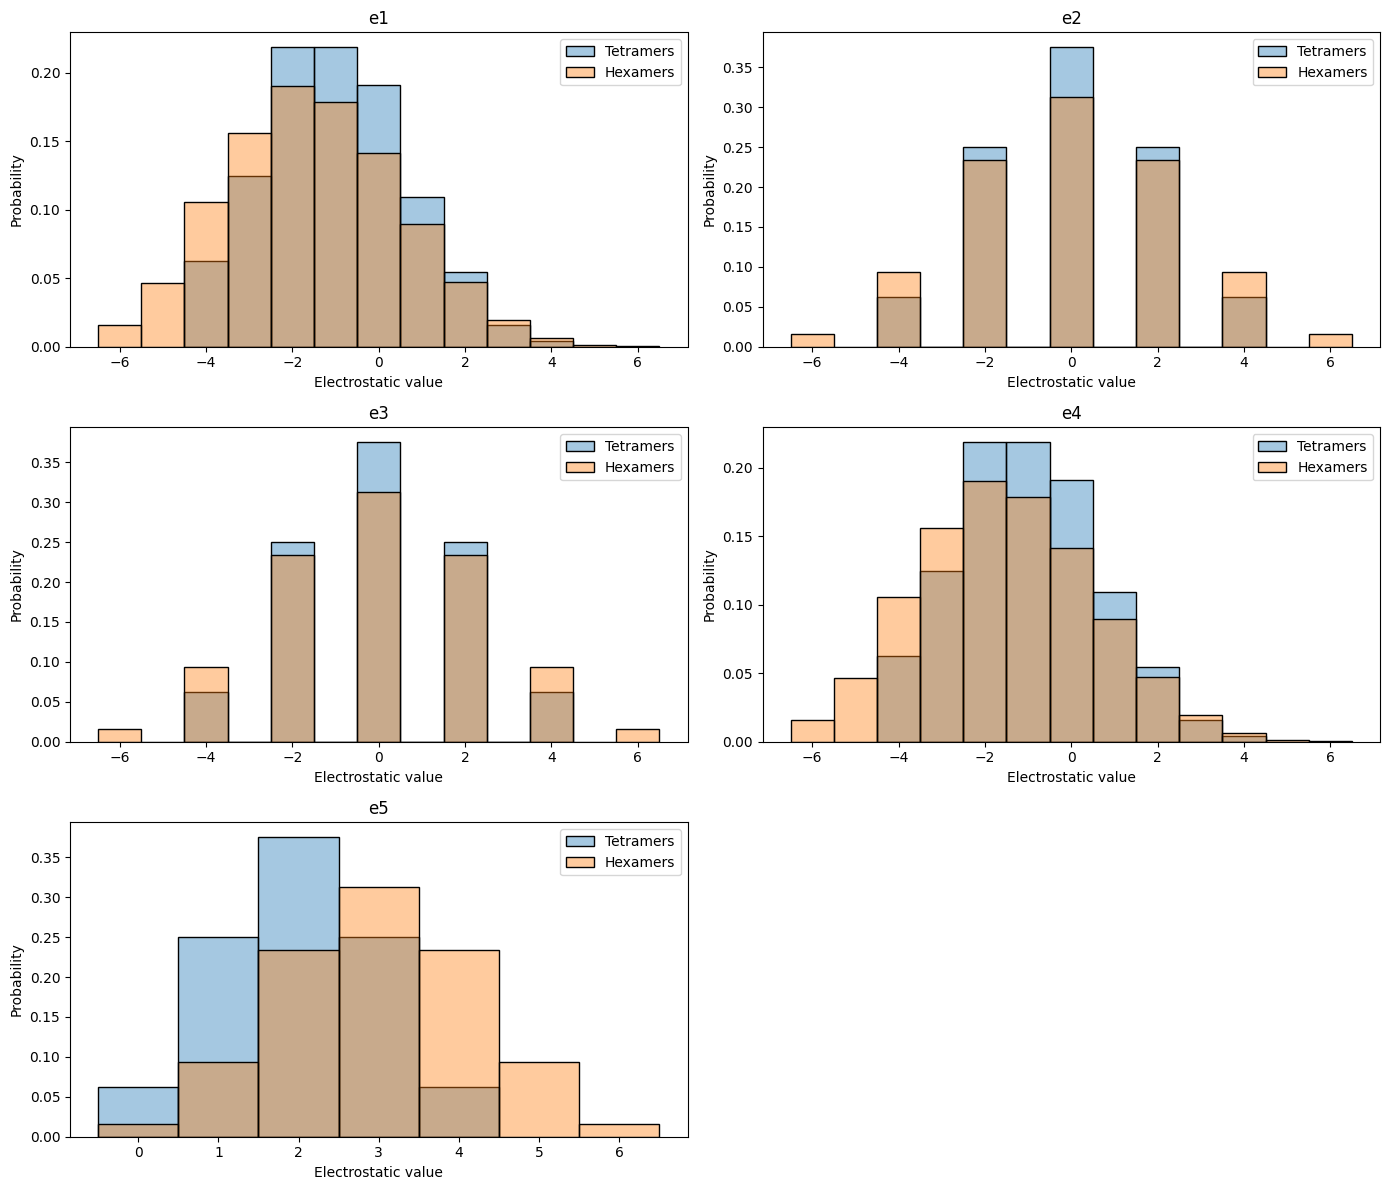

In [39]:
electrostatic_features = ["e1", "e2", "e3", "e4", "e5"]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, feature in zip(axes.flat, electrostatic_features):
    sns.histplot(input_tetramer[feature], discrete=True, stat="probability",
                 label="Tetramers", ax=ax, alpha=0.4)

    sns.histplot(input_hexamer[feature], discrete=True, stat="probability",
                 label="Hexamers", ax=ax, alpha=0.4)

    ax.set_title(feature)
    ax.set_xlabel("Electrostatic value")
    ax.set_ylabel("Probability")
    ax.legend()

# Remove the unused subplot
fig.delaxes(axes.flat[-1])

plt.tight_layout()
fig.savefig("electrostatic_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The electrostatic descriptors show discrete distributions, with different patterns depending on the feature.

e1 and e4 are predominantly negative, with values concentrated around −2. In contrast, e2 and e3 show approximately symmetric distributions centred around zero, where zero is the most frequent value.

e5 presents a predominantly positive distribution, with values concentrated between 1 and 4. Hexamers show a shift towards higher values compared with tetramers, consistent with their higher mean.

Overall, the hexamer descriptors cover a wider range of values (−6 to +6) than the tetramer descriptors (−4 to +4). This is consistent with the longer sequence length and the accumulation of contributions from additional bases.

These results show that the five electrostatic descriptors capture different chemical patterns rather than following a common distribution.

### 5.4. Ion-related descriptors

In this section, we examine the distributions of the ion-related descriptors obtained from the ion vector datasets.

The tetramer dataset contains six descriptors (`m1`–`m3` and `j1`–`j3`), whereas the hexamer dataset contains ten descriptors (`m0`–`m4` and `j0`–`j4`).

Since the repository does not document the physical meaning of these descriptors, the analysis focuses on their numerical distributions, variability and differences between tetramers and hexamers.

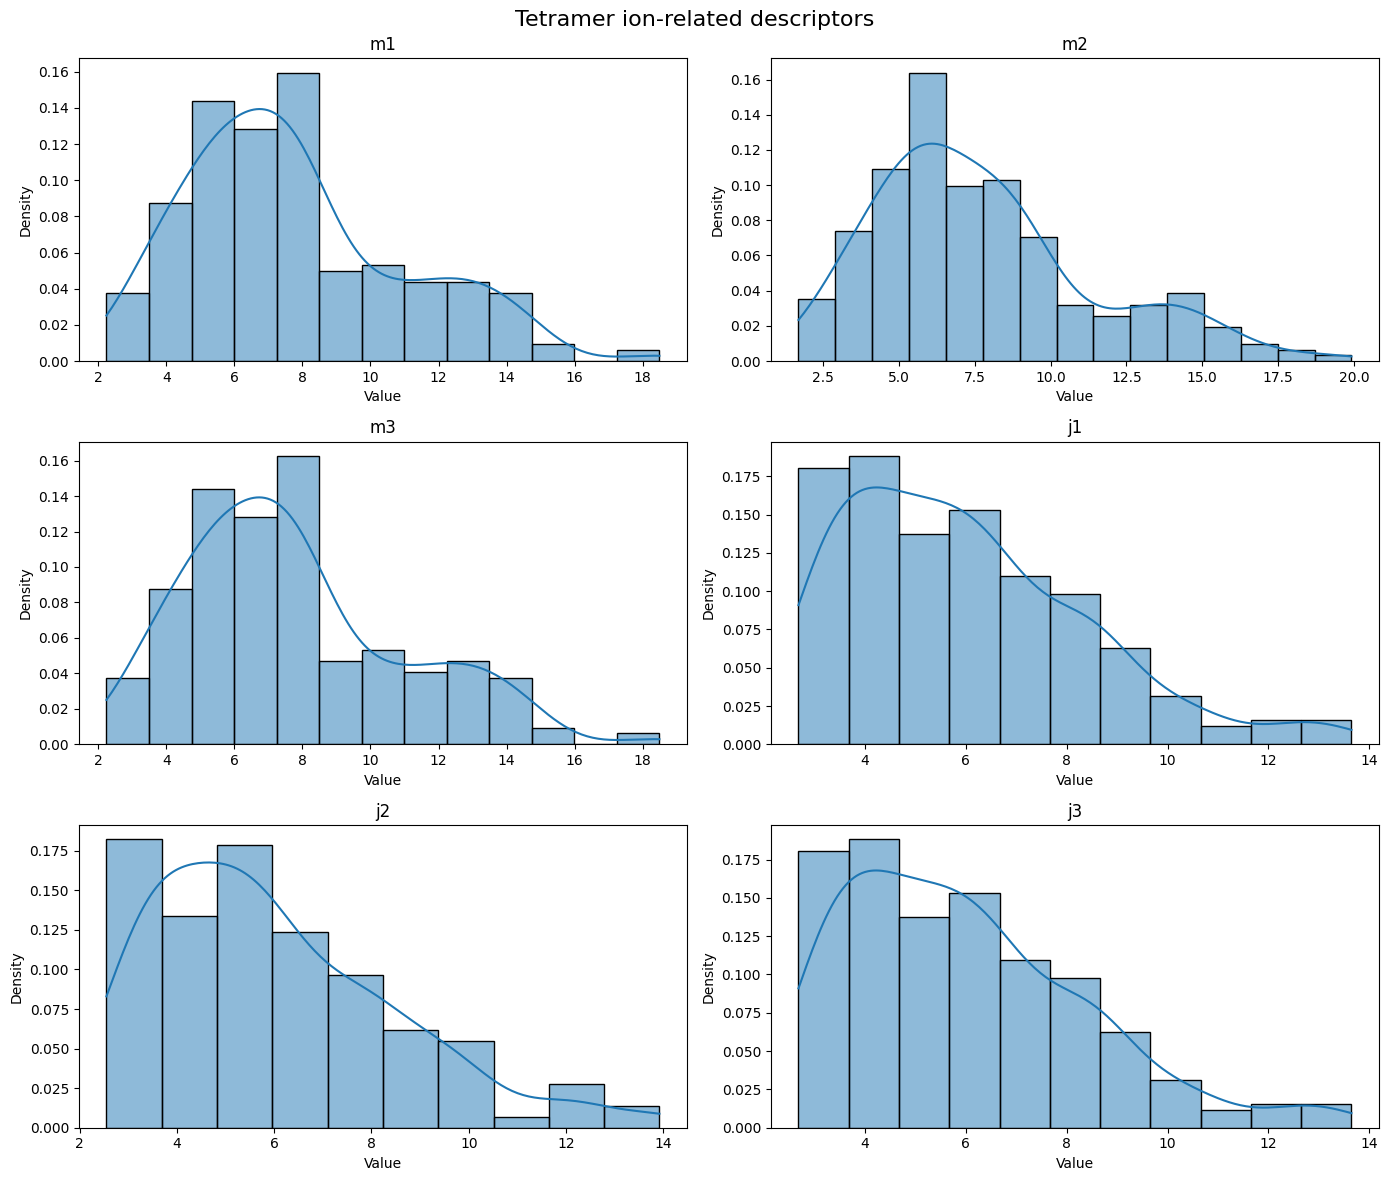

In [40]:
tetramer_ion_features = ["m1", "m2", "m3", "j1", "j2", "j3"]
hexamer_ion_features = ["m0", "m1", "m2", "m3", "m4",
                        "j0", "j1", "j2", "j3", "j4"]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, feature in zip(axes.flat, tetramer_ion_features):
    sns.histplot(input_tetramer[feature], kde=True, stat="density", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")

plt.suptitle("Tetramer ion-related descriptors", fontsize=16)
plt.tight_layout()
fig.savefig("tetramer_ion_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

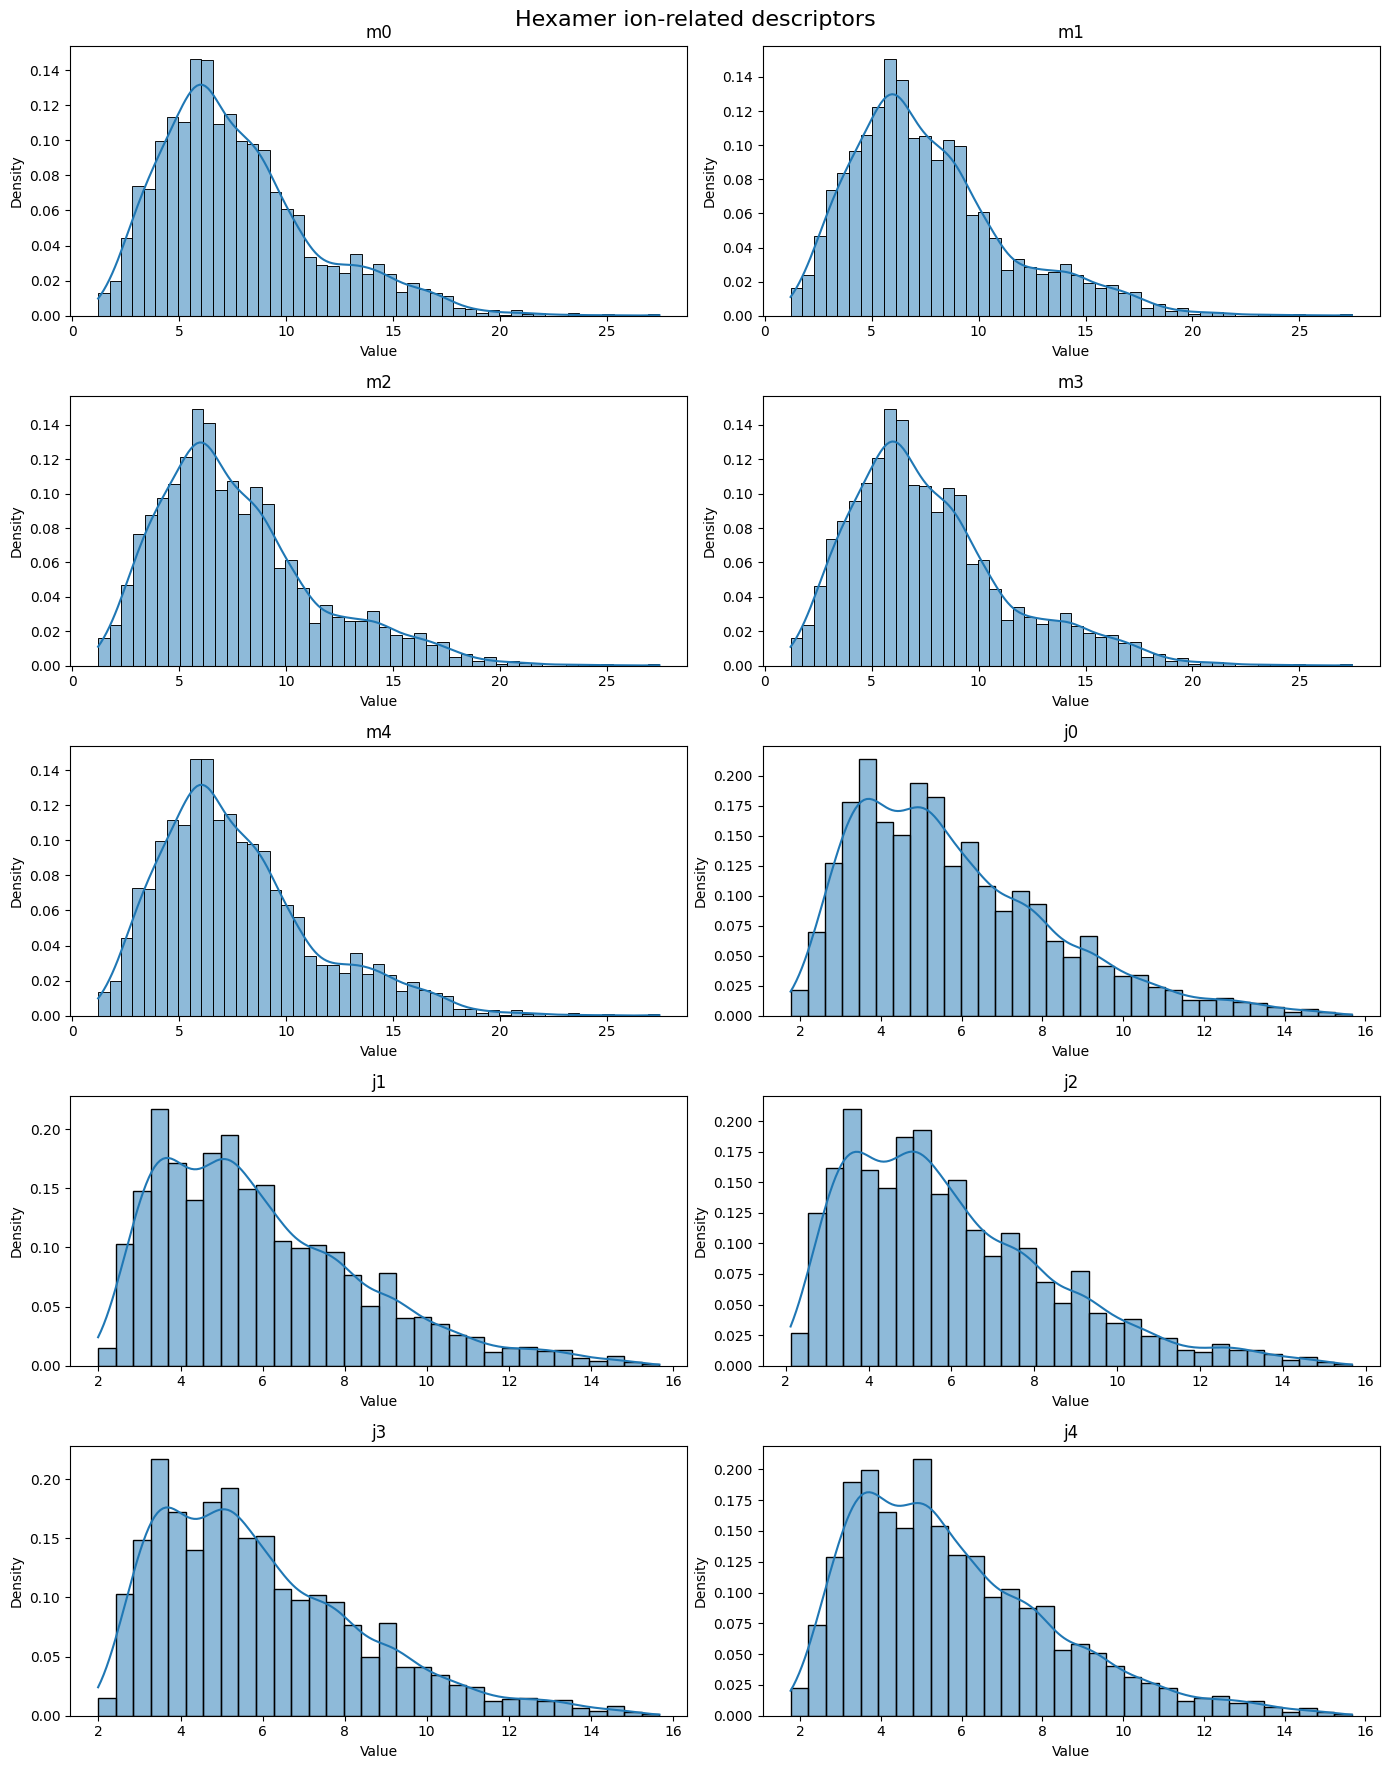

In [41]:
fig, axes = plt.subplots(5, 2, figsize=(14, 18))

for ax, feature in zip(axes.flat, hexamer_ion_features):
    sns.histplot(input_hexamer[feature], kde=True, stat="density", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")

plt.suptitle("Hexamer ion-related descriptors", fontsize=16)
plt.tight_layout()
fig.savefig("hexamer_ion_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The ion-related descriptors show predominantly right-skewed distributions, with most observations concentrated at lower values and longer tails towards higher values.

For tetramers, the `m1`–`m3` descriptors show similar distributions, with most values concentrated between approximately 4 and 9. The `j1`–`j3` descriptors also have similar distributions, although their values are generally concentrated at lower ranges.

A similar pattern is observed for hexamers. The `m0`–`m4` descriptors show right-skewed distributions, with values concentrated mainly between 5 and 10. The `j0`–`j4` descriptors also show right skewness, with most values concentrated between approximately 3 and 7.

Overall, the distributions are relatively similar within the `m` and `j` groups. However, their different numerical ranges and variability suggest that these descriptors should be examined further through correlation analysis.

## 6. Correlation Analysis

In this section, we investigate the relationships between the numerical features in the tetramer and hexamer datasets.

Correlation analysis allows us to identify features that vary together, detect potential redundancy and understand relationships between different structural and physicochemical properties.

We use Pearson correlation coefficients to measure the strength and direction of linear relationships between pairs of features.

### 6.1. Correlation between average helical parameters (AVG)

We first examine the correlations between the six average helical parameters (SHIFT, SLIDE, RISE, TILT, ROLL and TWIST).

Pearson correlation coefficients are calculated separately for tetramers and hexamers. The results are visualised using correlation heatmaps to identify positive and negative relationships between the structural parameters.

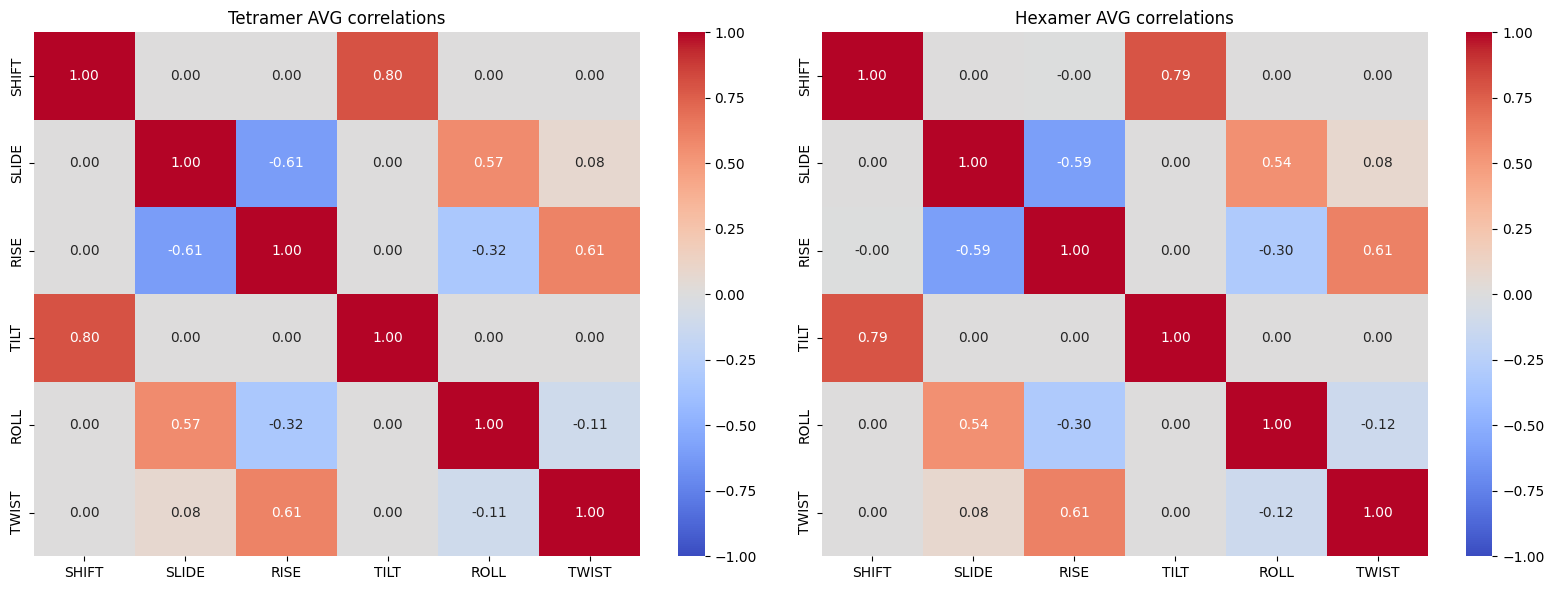

In [42]:
avg_features = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]

# Calculate Pearson correlation matrices
corr_avg_tetramer = input_tetramer[avg_features].corr(method="pearson")
corr_avg_hexamer = input_hexamer[avg_features].corr(method="pearson")

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(corr_avg_tetramer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[0])

axes[0].set_title("Tetramer AVG correlations")

sns.heatmap(corr_avg_hexamer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[1])

axes[1].set_title("Hexamer AVG correlations")

plt.tight_layout()
fig.savefig("avg_correlation_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The correlation analysis reveals several relationships between the average helical parameters.

The strongest correlation is observed between SHIFT and TILT, with a Pearson correlation coefficient of approximately 0.80 in tetramers and 0.79 in hexamers. This indicates a strong positive relationship between these two parameters.

Other notable correlations include a negative relationship between SLIDE and RISE (approximately −0.61 in tetramers and −0.59 in hexamers), and positive relationships between RISE and TWIST (0.61 in both datasets) and between SLIDE and ROLL (0.57 and 0.54, respectively).

Most of the remaining parameter pairs show weak or negligible linear correlations.

The correlation patterns are remarkably similar between tetramers and hexamers, suggesting that the relationships between their average helical parameters are largely conserved.

Overall, these results indicate that some structural parameters are correlated, meaning that they do not vary completely independently across DNA sequences.

### 6.2. Correlation between stiffness matrix elements (FCE)

We now investigate the correlations between the elements of the stiffness matrix.

Since the stiffness matrix is symmetric, it contains 21 unique elements: six diagonal elements and fifteen off-diagonal elements. Only these unique elements are considered to avoid including duplicated information.

Pearson correlation coefficients are calculated separately for tetramers and hexamers. The resulting heatmaps allow us to identify relationships between different deformation modes and potential redundancy among the stiffness features.

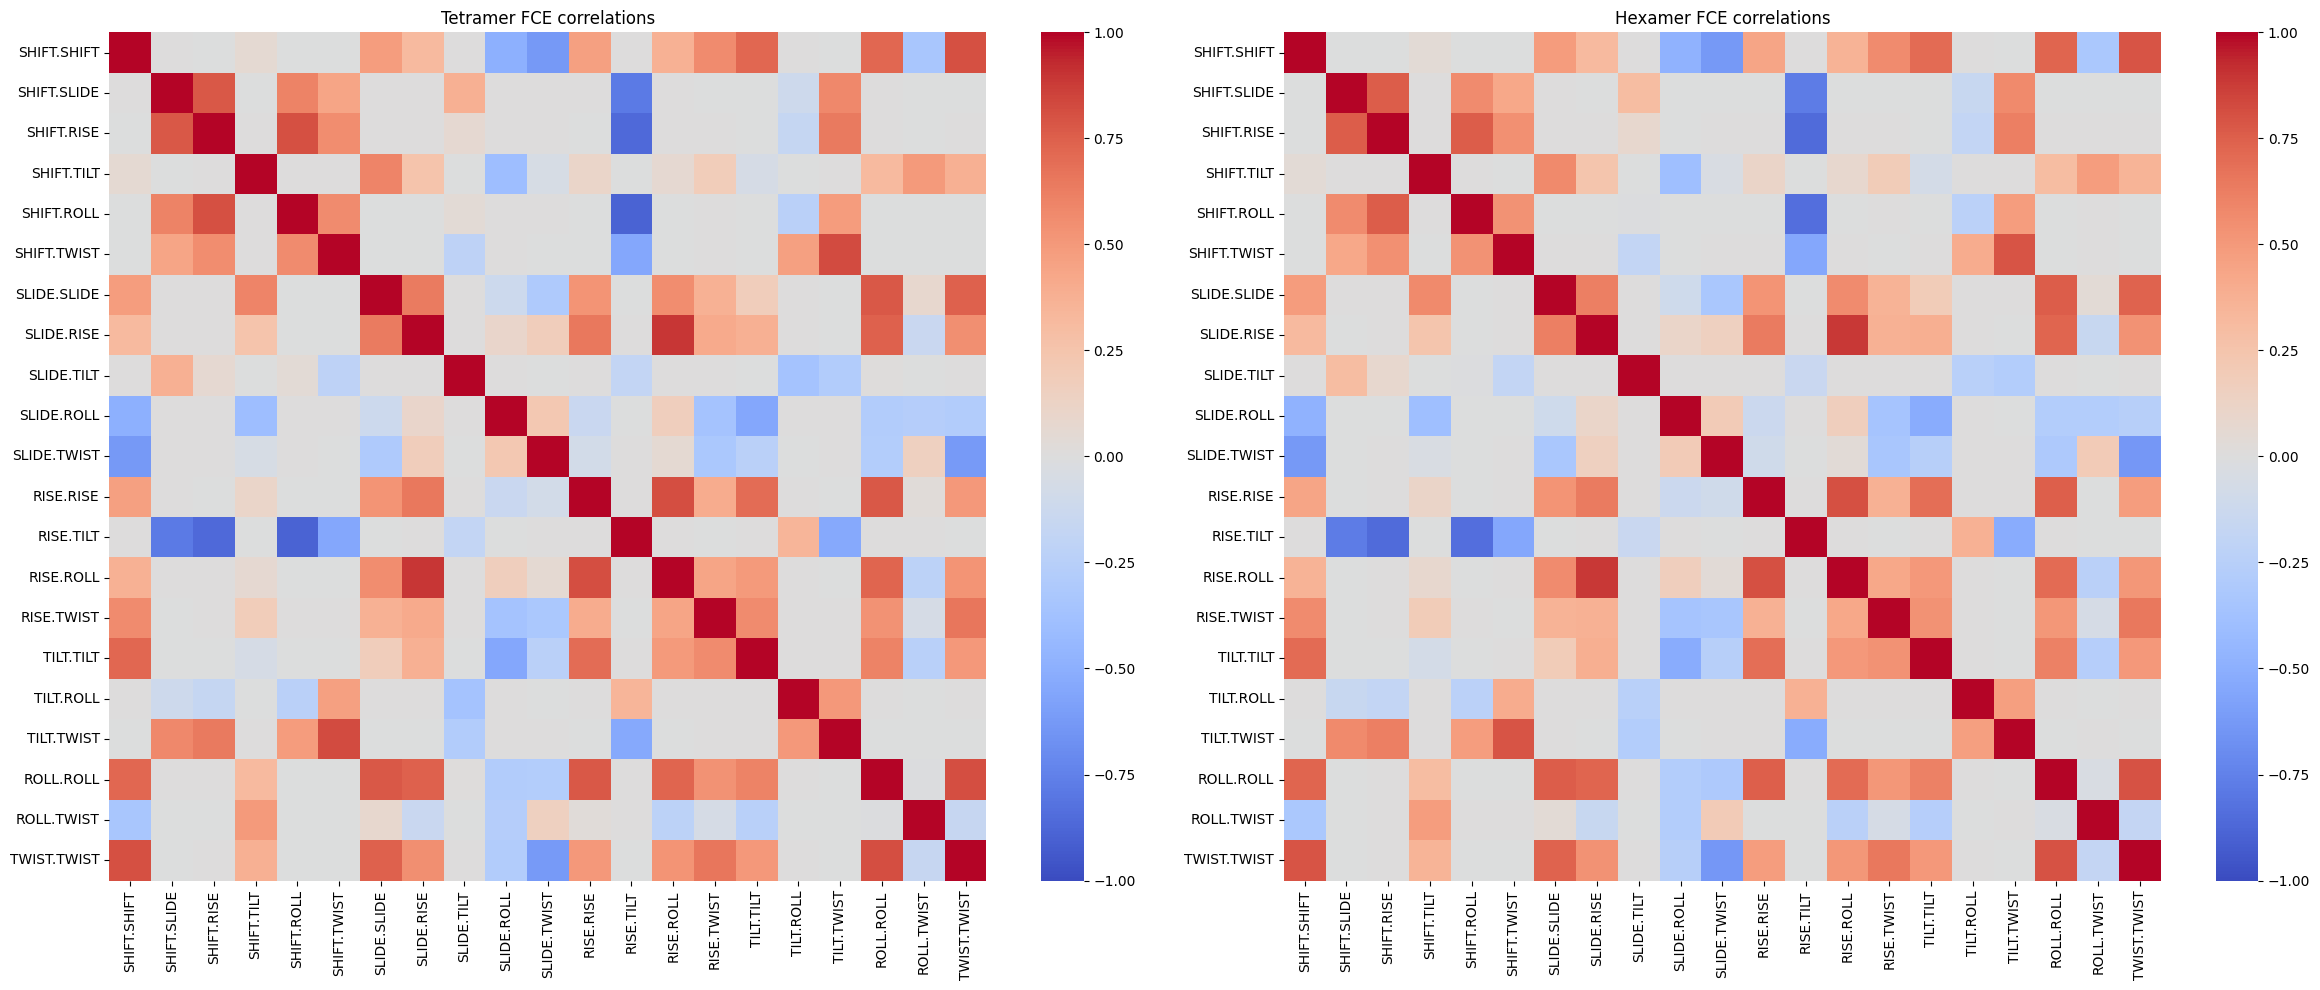

In [44]:
import itertools

degrees = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]

# Generate the 21 unique stiffness matrix elements
fce_features = [
    f"{a}.{b}"
    for i, a in enumerate(degrees)
    for b in degrees[i:]
]

# Calculate Pearson correlation matrices
corr_fce_tetramer = input_tetramer[fce_features].corr(method="pearson")
corr_fce_hexamer = input_hexamer[fce_features].corr(method="pearson")

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

sns.heatmap(corr_fce_tetramer, cmap="coolwarm", vmin=-1, vmax=1,
            center=0, ax=axes[0])

axes[0].set_title("Tetramer FCE correlations")

sns.heatmap(corr_fce_hexamer, cmap="coolwarm", vmin=-1, vmax=1,
            center=0, ax=axes[1])

axes[1].set_title("Hexamer FCE correlations")

plt.tight_layout()
fig.savefig("fce_correlation_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The correlation analysis reveals a complex structure of relationships between the stiffness matrix elements.

Several features show strong positive correlations, indicating that their values tend to increase or decrease together across DNA sequences. Other features, particularly RISE.TILT, show negative correlations with several coupling terms, suggesting that these stiffness components tend to vary in opposite directions.

In contrast, many pairs of features show weak or negligible linear correlations, indicating that not all stiffness components vary together.

The tetramer and hexamer correlation heatmaps show remarkably similar patterns, suggesting that the relationships between the stiffness elements are largely conserved between both datasets.

Overall, the results indicate that some stiffness features are strongly correlated, suggesting potential redundancy among certain descriptors. This will be important to consider in subsequent analyses and dimensionality reduction.

### 6.3. Correlation between electrostatic descriptors

We now investigate the relationships between the five electrostatic descriptors (`e1`–`e5`).

Pearson correlation coefficients are calculated separately for tetramers and hexamers and visualised using correlation heatmaps.

This analysis allows us to identify relationships between the different electrostatic descriptors and investigate whether some features provide similar information.

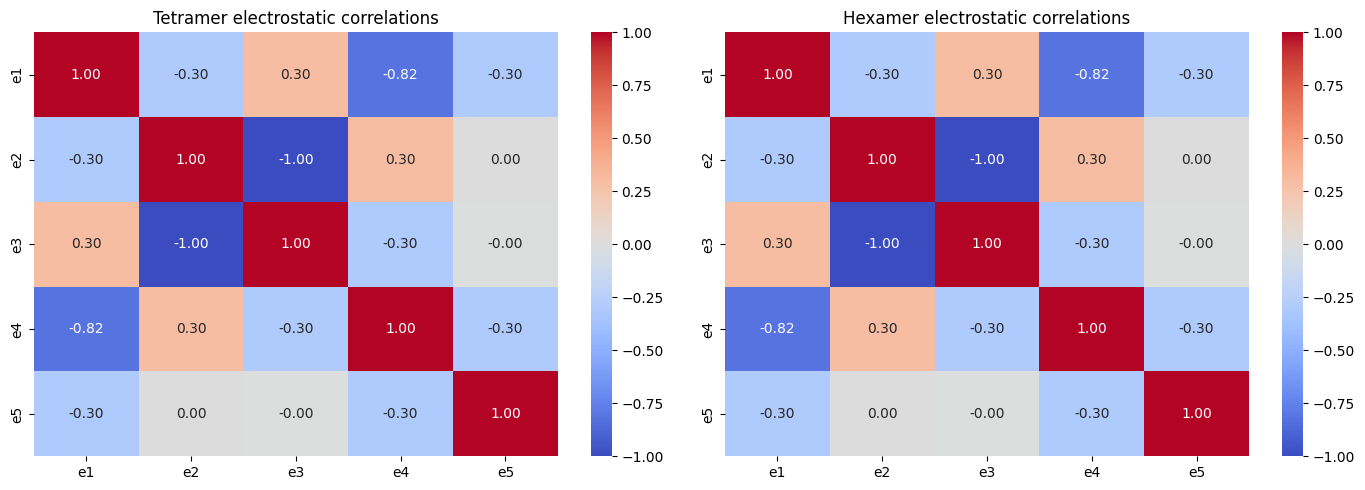

In [45]:
electrostatic_features = ["e1", "e2", "e3", "e4", "e5"]

# Calculate Pearson correlation matrices
corr_elec_tetramer = input_tetramer[electrostatic_features].corr(method="pearson")
corr_elec_hexamer = input_hexamer[electrostatic_features].corr(method="pearson")

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr_elec_tetramer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[0])

axes[0].set_title("Tetramer electrostatic correlations")

sns.heatmap(corr_elec_hexamer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[1])

axes[1].set_title("Hexamer electrostatic correlations")

plt.tight_layout()
fig.savefig("electrostatic_correlation_heatmaps.png",
            dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The correlation analysis reveals strong relationships between some electrostatic descriptors.

The strongest relationship is observed between e2 and e3, which show a perfect negative correlation (−1.00) in both datasets. This indicates that these two features have an exact inverse linear relationship and therefore contain redundant linear information.

A strong negative correlation is also observed between e1 and e4 (−0.82), suggesting considerable overlap between these descriptors.

The remaining feature pairs show weak to moderate correlations, with coefficients ranging approximately from −0.30 to +0.30. In particular, e5 shows relatively weak correlations with the other descriptors.

An interesting finding is that the tetramer and hexamer correlation matrices are identical, indicating that the relationships between the electrostatic descriptors are preserved across both datasets.

Overall, these results suggest that some electrostatic descriptors contain redundant information, particularly e2 and e3. This will be relevant when investigating feature dimensionality and potential redundancy.

### 6.4. Correlation between ion-related descriptors

In this section, we investigate the correlations between the ion-related descriptors.

Pearson correlation coefficients are calculated separately for tetramers and hexamers, considering their respective sets of six and ten features.

The resulting correlation heatmaps allow us to identify relationships between the descriptors and investigate whether some columns contain overlapping information.

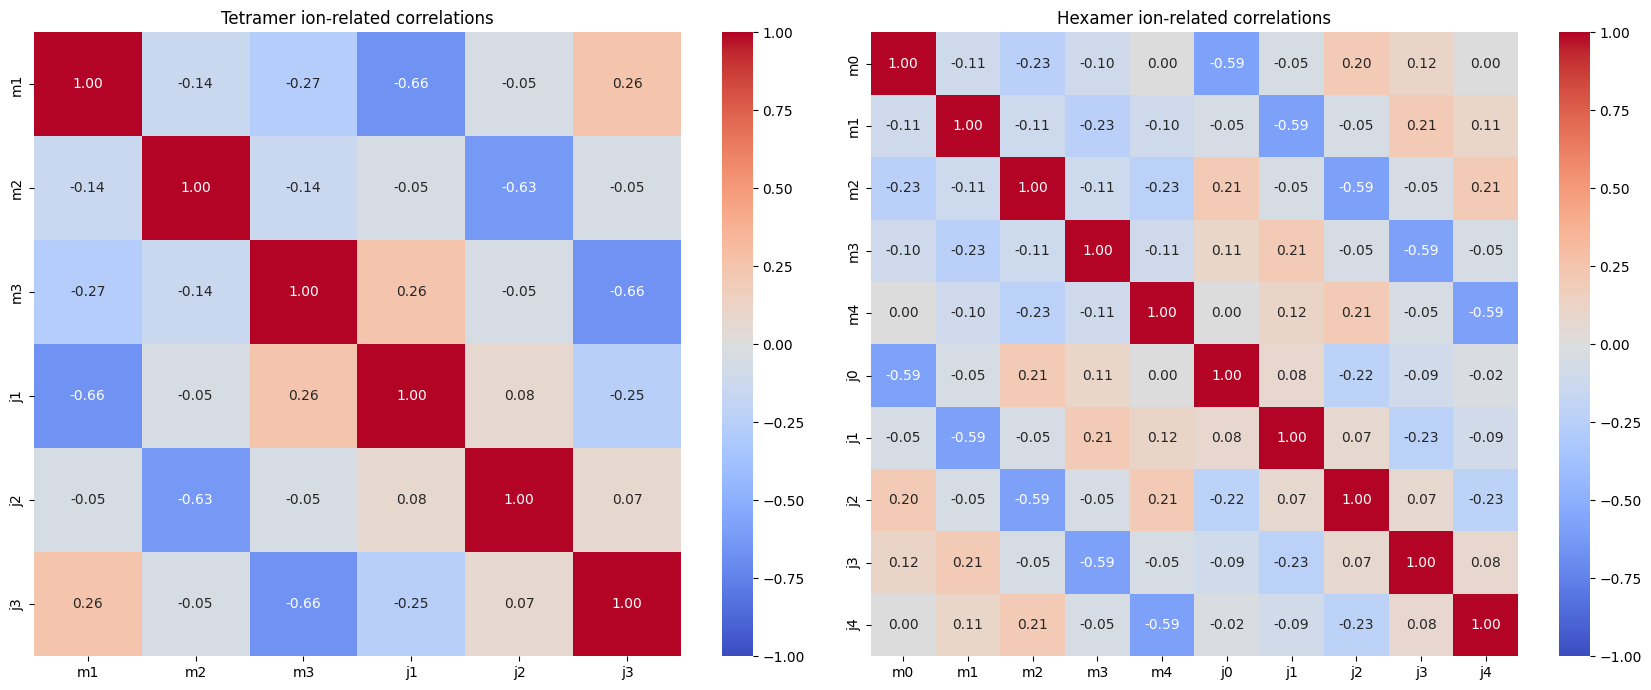

In [46]:
tetramer_ion_features = ["m1", "m2", "m3", "j1", "j2", "j3"]

hexamer_ion_features = [
    "m0", "m1", "m2", "m3", "m4",
    "j0", "j1", "j2", "j3", "j4"
]

# Calculate Pearson correlation matrices
corr_ion_tetramer = input_tetramer[tetramer_ion_features].corr()
corr_ion_hexamer = input_hexamer[hexamer_ion_features].corr()

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

sns.heatmap(corr_ion_tetramer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[0])

axes[0].set_title("Tetramer ion-related correlations")

sns.heatmap(corr_ion_hexamer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[1])

axes[1].set_title("Hexamer ion-related correlations")

plt.tight_layout()
fig.savefig("ion_correlation_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The correlation analysis reveals a consistent negative relationship between corresponding `m` and `j` descriptors.

In tetramers, the strongest correlations are observed between m1 and j1 (−0.66), m2 and j2 (−0.63), and m3 and j3 (−0.66).

A similar pattern is observed in hexamers, where the corresponding pairs (m0–j0, m1–j1, m2–j2, m3–j3 and m4–j4) all show negative correlations of approximately −0.59.

Most other feature pairs show relatively weak correlations.

Overall, the results indicate that corresponding `m` and `j` descriptors share some linear information. These relationships are consistent between tetramers and hexamers, although their precise physical interpretation remains unknown.

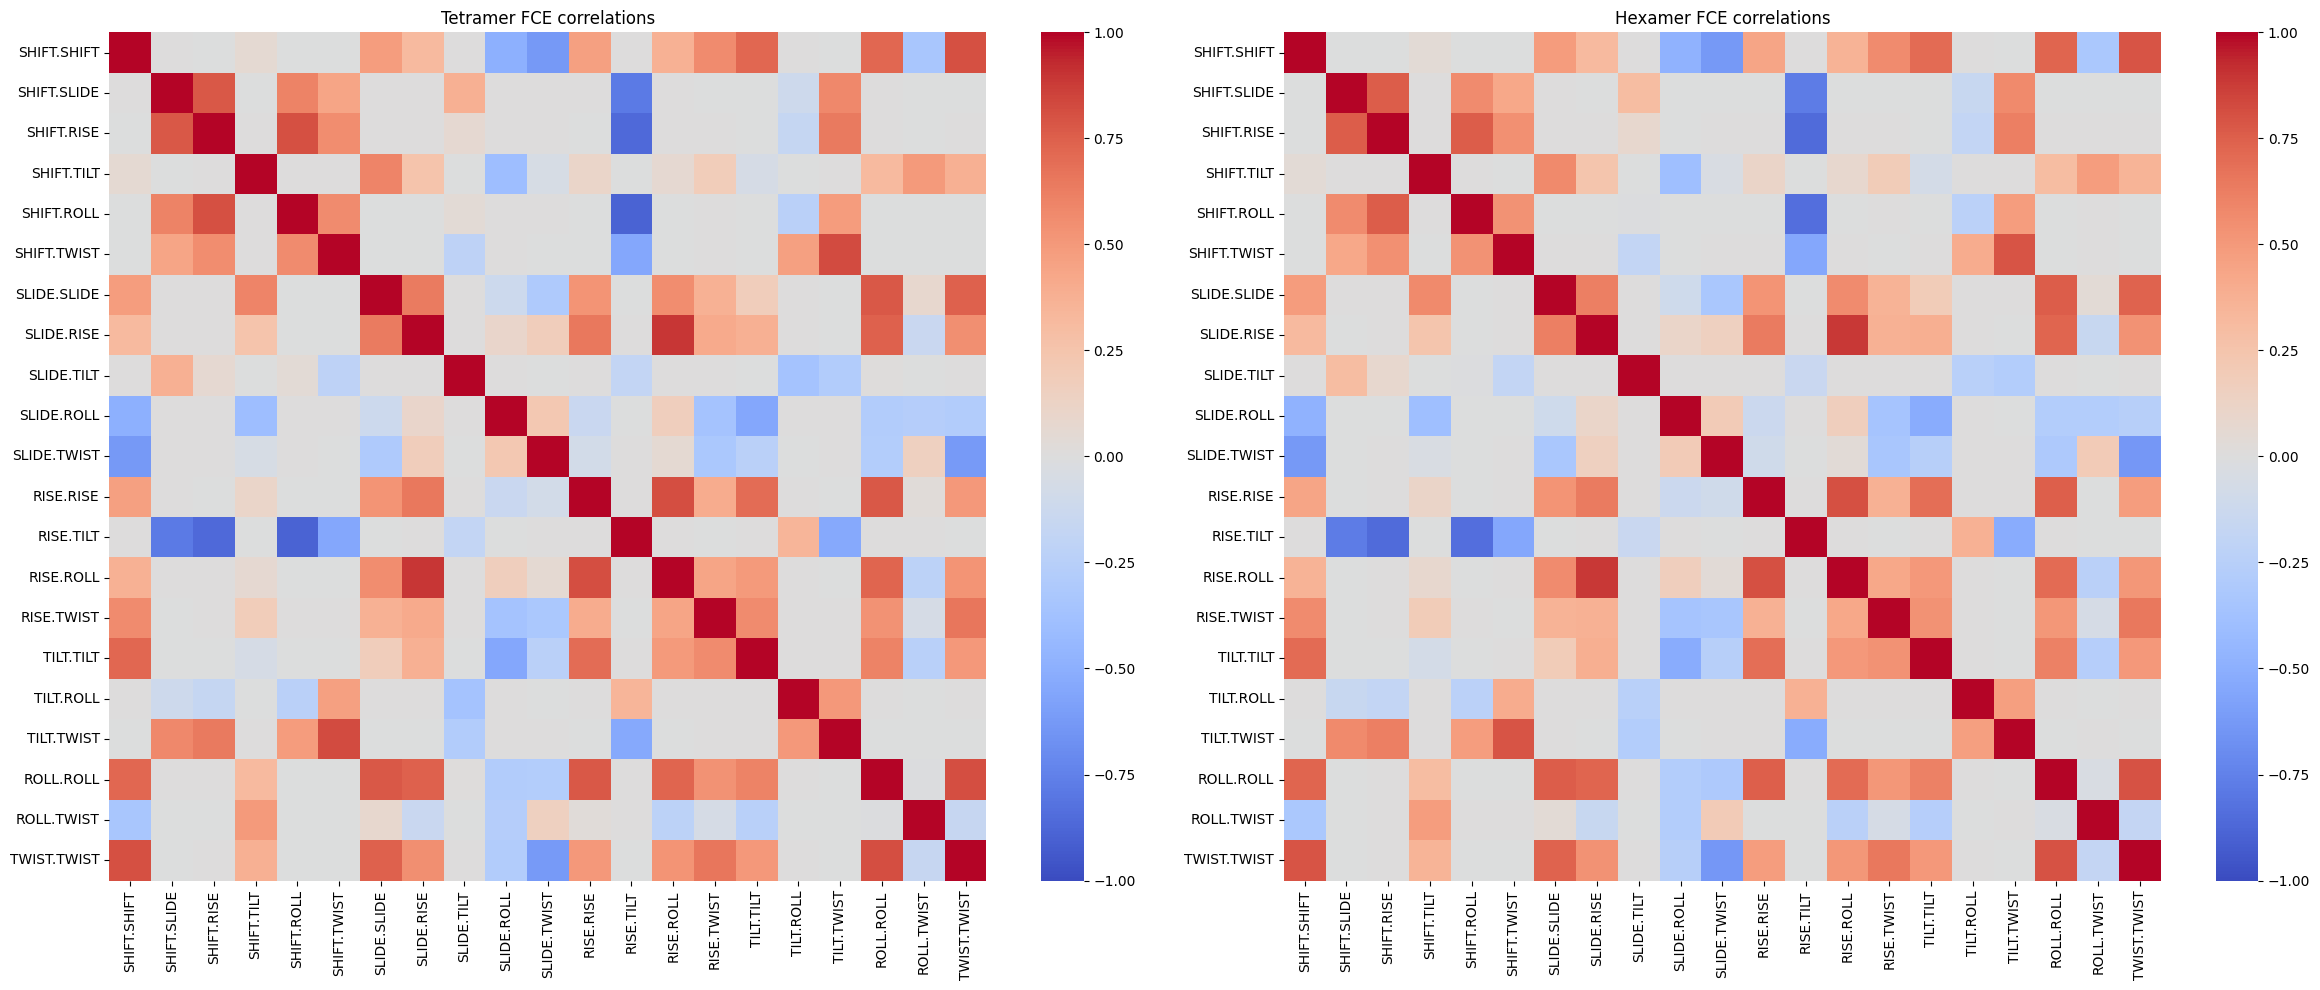

In [ ]:
import itertools

degrees = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]

# Generate the 21 unique stiffness matrix elements
fce_features = [
    f"{a}.{b}"
    for i, a in enumerate(degrees)
    for b in degrees[i:]
]

# Calculate Pearson correlation matrices
corr_fce_tetramer = input_tetramer[fce_features].corr(method="pearson")
corr_fce_hexamer = input_hexamer[fce_features].corr(method="pearson")

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

sns.heatmap(corr_fce_tetramer, cmap="coolwarm", vmin=-1, vmax=1,
            center=0, ax=axes[0])

axes[0].set_title("Tetramer FCE correlations")

sns.heatmap(corr_fce_hexamer, cmap="coolwarm", vmin=-1, vmax=1,
            center=0, ax=axes[1])

axes[1].set_title("Hexamer FCE correlations")

plt.tight_layout()
fig.savefig("fce_correlation_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The correlation analysis reveals a consistent negative relationship between corresponding `m` and `j` descriptors.

In tetramers, the strongest correlations are observed between m1 and j1 (−0.66), m2 and j2 (−0.63), and m3 and j3 (−0.66).

A similar pattern is observed in hexamers, where the corresponding pairs (m0–j0, m1–j1, m2–j2, m3–j3 and m4–j4) all show negative correlations of approximately −0.59.

Most other feature pairs show relatively weak correlations.

Overall, the results indicate that corresponding `m` and `j` descriptors share some linear information. These relationships are consistent between tetramers and hexamers, although their precise physical interpretation remains unknown.

## 7. Feature Structure and Dimensionality

In this section, we investigate the structure and dimensionality of the tetramer and hexamer feature datasets.

Although the datasets contain 53 and 57 numerical features, respectively, some descriptors may contain redundant or linearly dependent information.

We examine the symmetry of the stiffness matrices, the dimensionality of the electrostatic descriptors and the reverse-complement properties of the ion-related features.

These analyses will help us understand the amount of independent information represented by the available features.

## 7. Feature Structure and Dimensionality

In this section, we examine additional properties of the structural and physicochemical descriptors, focusing on feature redundancy, dimensionality and reverse-complement symmetry.

### 7.1. Electrostatic feature dimensionality

The five electrostatic descriptors (`e1`–`e5`) do not represent five independent dimensions.

For tetramers, the 256 possible sequences produce only 35 unique electrostatic profiles. For hexamers, the 4,096 sequences produce 84 unique profiles.

Furthermore, both electrostatic feature matrices have a rank of 3, indicating that the five descriptors span only three linearly independent dimensions. This reveals the presence of linear dependencies and redundancy among these features.

### 7.2. Reverse-complement symmetry of ion-related descriptors

The ion-related descriptors exhibit very strong correlations under reverse-complement transformation.

For tetramers, all six descriptors show correlations above 0.9999. For hexamers, the correlations range from approximately 0.9960 to 1.0000.

These results indicate that the ion-related features are highly consistent between reverse-complementary sequences, although the values are not always exactly identical.

### 8.1. Dataset overview

We first examine the structure of the HT-SELEX datasets selected for each transcription factor. The datasets correspond to different SELEX cycles and contain information about observed 10-mers, their estimated binding affinities and sequencing counts.

The aim is to compare the size and structure of the datasets and verify that they contain consistent information before performing further analyses.

In [54]:
for protein, df in selex_data.items():
    print(f"{protein} (cycle {selex_cycles[protein]})")
    print(f"  Dimensions: {df.shape}")
    print(f"  Columns: {df.columns.tolist()}")
    print()

Gata4 (cycle 4)
  Dimensions: (126624, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

Zfp24 (cycle 5)
  Dimensions: (406165, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

arid3 (cycle 6)
  Dimensions: (273249, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

hoxd1 (cycle 3)
  Dimensions: (887634, 7)
  Columns: ['#', 'Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

nkx3 (cycle 6)
  Dimensions: (963575, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

pax3-like (cycle 5)
  Dimensions: (427916, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

six1 (cycle 5)
  Dimensions: (944350, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

tbx15 (cycle 5)
  Dimensions: (25991, 6)
  Columns: ['Kmer', 'ObservedCount', 'Prob

In [57]:
selex_data["hoxd1"] = selex_data["hoxd1"].drop(columns="#")

# Verify that all datasets now have the same columns
for protein, df in selex_data.items():
    print(f"{protein}: {df.shape[1]} columns")

Gata4: 6 columns
Zfp24: 6 columns
arid3: 6 columns
hoxd1: 6 columns
nkx3: 6 columns
pax3-like: 6 columns
six1: 6 columns
tbx15: 6 columns
telf: 6 columns
uncxb: 6 columns
xbpc: 6 columns


### 8.1. Dataset overview

The 11 HT-SELEX datasets correspond to different transcription factors and selected SELEX cycles. Each dataset contains observed 10-mer sequences together with their sequencing counts, estimated affinities and associated statistical information.

The number of observed sequences varies considerably between transcription factors, ranging from 25,991 for Tbx15 to 963,575 for Nkx3.

The initial data inspection revealed that:

- All datasets contain sequences of exactly 10 nucleotides.
- No missing values were detected.
- No duplicated K-mers were found within any dataset.
- All datasets initially contained the same six biological columns: `Kmer`, `ObservedCount`, `Probability`, `ExpectedCount`, `Affinity` and `SE`.

The Hoxd1 dataset contained an additional `#` column, corresponding to a sequential row index. This column was removed to ensure consistency across all datasets.

After preprocessing, all 11 datasets share the same structure and are ready for further exploratory analysis.

In [58]:
selex_stats = []

for protein, df in selex_data.items():
    for variable in ["ObservedCount", "Affinity"]:
        stats = df[variable].describe()

        selex_stats.append({
            "Transcription factor": protein,
            "Variable": variable,
            "Mean": stats["mean"],
            "Median": stats["50%"],
            "Std": stats["std"],
            "Min": stats["min"],
            "Max": stats["max"]
        })

selex_stats = pd.DataFrame(selex_stats)
display(selex_stats.round(4))

,Transcription factor,Variable,Mean,Median,Std,Min,Max
0,Gata4,ObservedCount,5.4461,1.0000,19.7855,1.0000,925.0000
1,Gata4,Affinity,0.2349,0.2140,0.0831,0.0942,1.0000
2,Zfp24,ObservedCount,24.6974,2.0000,139.5192,1.0000,9031.0000
3,Zfp24,Affinity,0.2733,0.2555,0.0711,0.1417,1.0000
4,arid3,ObservedCount,8.9125,2.0000,65.7976,1.0000,12365.0000
5,arid3,Affinity,0.2777,0.2680,0.0539,0.1595,1.0000
6,hoxd1,ObservedCount,3.8803,3.0000,6.1556,1.0000,520.0000
7,hoxd1,Affinity,0.0172,0.0140,0.0136,0.0010,0.5843
8,nkx3,ObservedCount,8.9979,5.0000,11.3716,1.0000,727.0000
9,nkx3,Affinity,0.3605,0.3554,0.0554,0.1873,1.0000


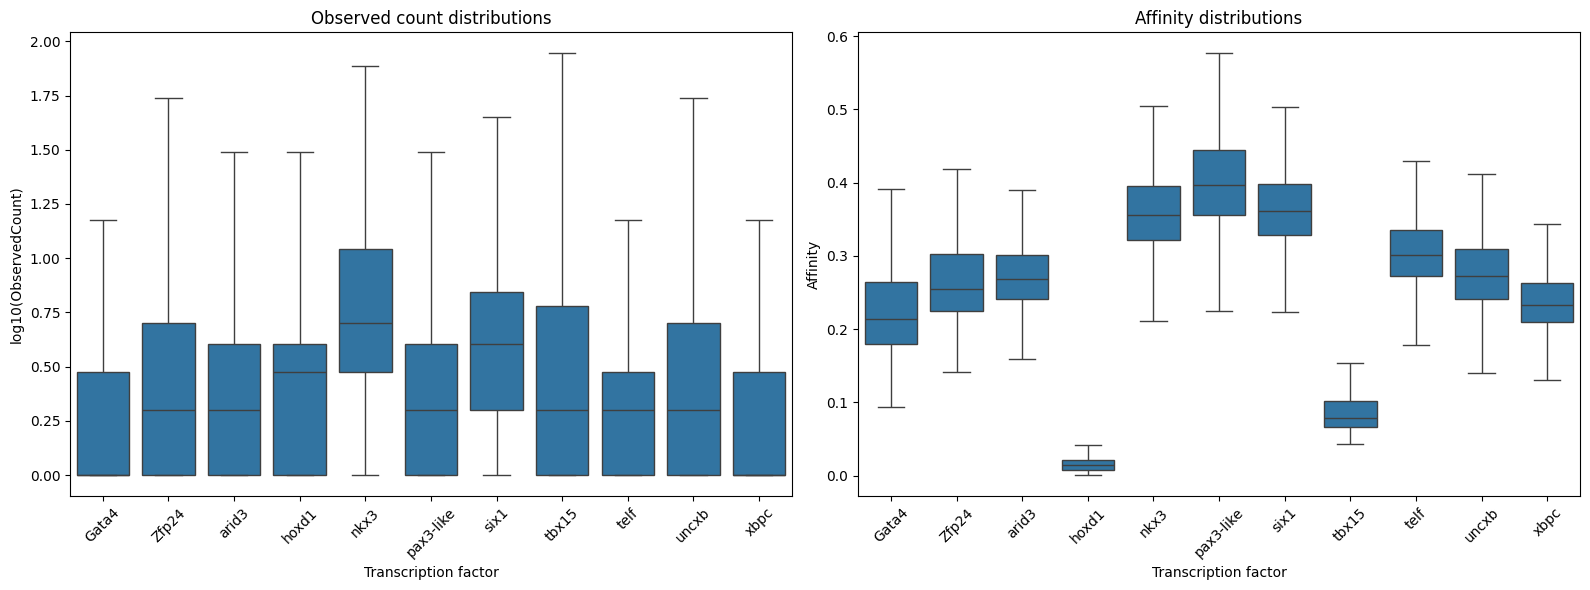

In [60]:
# Combine all datasets into a single DataFrame
selex_combined = pd.concat(
    [
        df.assign(TranscriptionFactor=protein)
        for protein, df in selex_data.items()
    ],
    ignore_index=True
)

# Log-transform observed counts
selex_combined["Log10ObservedCount"] = np.log10(
    selex_combined["ObservedCount"]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Observed counts
sns.boxplot(
    data=selex_combined,
    x="TranscriptionFactor",
    y="Log10ObservedCount",
    ax=axes[0],
    showfliers=False
)
axes[0].set_title("Observed count distributions")
axes[0].set_xlabel("Transcription factor")
axes[0].set_ylabel("log10(ObservedCount)")
axes[0].tick_params(axis="x", rotation=45)

# Affinity
sns.boxplot(
    data=selex_combined,
    x="TranscriptionFactor",
    y="Affinity",
    ax=axes[1],
    showfliers=False
)
axes[1].set_title("Affinity distributions")
axes[1].set_xlabel("Transcription factor")
axes[1].set_ylabel("Affinity")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()

fig.savefig(
    "selex_count_affinity_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The observed count distributions are highly right-skewed across the transcription factors, with most K-mers having relatively low counts and a small proportion showing much higher abundance. Nkx3, Six1 and Hoxd1 have comparatively higher median counts, while Tbx15 shows particularly high variability.

The affinity distributions also differ considerably between transcription factors. Pax3-like, Nkx3 and Six1 exhibit the highest median affinities, whereas Hoxd1 and Tbx15 have substantially lower values. The remaining transcription factors show intermediate affinity distributions.

These differences highlight the variability in sequencing counts and estimated affinities across the HT-SELEX datasets. Therefore, the distributions should be considered when designing subsequent preprocessing and modelling steps.

### 8.2. Observed counts and affinity

We calculate the Spearman correlation between `ObservedCount` and `Affinity` separately for each transcription factor.

In [61]:
selex_correlations = []

for protein, df in selex_data.items():
    correlation = df["ObservedCount"].corr(
        df["Affinity"],
        method="spearman"
    )

    selex_correlations.append({
        "Transcription factor": protein,
        "Spearman correlation": correlation
    })

selex_correlations = pd.DataFrame(selex_correlations)
display(selex_correlations.round(4))

,Transcription factor,Spearman correlation
0,Gata4,0.7257
1,Zfp24,0.6178
2,arid3,0.6398
3,hoxd1,0.7922
4,nkx3,0.6358
5,pax3-like,0.5216
6,six1,0.5071
7,tbx15,0.8197
8,telf,0.5996
9,uncxb,0.5899


To investigate the relationship between sequencing abundance and estimated binding affinity, Spearman correlation coefficients were calculated separately for each transcription factor.

All 11 datasets showed positive correlations, ranging from 0.5071 for Six1 to 0.8197 for Tbx15. Hoxd1 (0.7922) and Gata4 (0.7257) also showed relatively strong associations.

These results indicate that K-mers with higher observed counts generally tend to have higher estimated affinity values. However, since affinity is derived from sequencing enrichment, this relationship is partly expected and should not be interpreted as independent evidence of biological binding strength.

In [62]:
se_stats = []

for protein, df in selex_data.items():
    stats = df["SE"].describe()

    se_stats.append({
        "Transcription factor": protein,
        "Mean SE": stats["mean"],
        "Median SE": stats["50%"],
        "Std SE": stats["std"],
        "Min SE": stats["min"],
        "Max SE": stats["max"]
    })

se_stats = pd.DataFrame(se_stats)
display(se_stats.round(5))

,Transcription factor,Mean SE,Median SE,Std SE,Min SE,Max SE
0,Gata4,0.22749,0.22773,0.06765,0.03788,0.59686
1,Zfp24,0.24668,0.25888,0.10488,0.00788,0.62348
2,arid3,0.26943,0.28284,0.09963,0.00838,0.60341
3,hoxd1,0.00921,0.00838,0.00426,0.00102,0.06250
4,nkx3,0.23664,0.21709,0.09864,0.04503,0.70351
5,pax3-like,0.40808,0.42279,0.14462,0.01083,0.91480
6,six1,0.27647,0.25974,0.10559,0.03905,0.77868
7,tbx15,0.07469,0.08005,0.02898,0.00175,0.15491
8,telf,0.31135,0.31428,0.09105,0.00948,0.63736
9,uncxb,0.26202,0.27207,0.11069,0.00777,0.68675
